# MMLU-Pro: subject and STEM/non-STEM comparisons

This notebook copies the loading, normalization, oracle, statistical tests, and analysis routines from `EDA_hung.ipynb`. It loads only MMLU-Pro evaluation outputs (including the MMLU-Pro subset) and runs the analyses twice: once by subject, then by STEM/non-STEM. Ensemble, exit-agreement, and hybrid simulations are removed; individual-method Pareto analysis remains.

Run all cells from the repository root. Set `OUTPUT_ROOT` below to your evaluation-output directory. Subjects are mapped by the persisted one-based `line_number` into the original dataloader test split (`rows[line_number - 1]`), never by output-file row order. The original loader discards `category`, so metadata is recovered from the matching original test split or a local metadata file in dataloader order. Full MMLU-Pro and the shuffled subset use separate row orders. Questions stored in `input` dictionaries are checked against the selected row when available. Unknown or ambiguous subjects stop the analysis rather than silently entering non-STEM.

STEM here means biology, chemistry, computer science, engineering, math, and physics. Health, psychology, business, economics, history, law, philosophy, and other are non-STEM under this explicit convention. Edit `STEM_SUBJECTS` if your study includes health or psychology in STEM.

Repeated runs are averaged per question before method comparisons. Subject macro averages weight each subject equally; STEM/non-STEM main summaries weight questions equally. Subjects and domains contain different questions, so between-group comparisons use independent-group tests; within-group method comparisons retain the original paired tests. These are observational comparisons, not effects caused by subject membership.


In [1]:
# !pip install scipy scikit-learn seaborn matplotlib pandas tabulate

In [2]:
import json, re
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_rel, wilcoxon

try:
    import seaborn as sns; sns.set_theme(style="whitegrid")
except ImportError:
    sns = None

VISUAL_TOKEN_CAP = 32_000
FAILED_THINKING_TOKENS = 32_000

def token_p95(values):
    """Return the 95th percentile for a token-consumption series."""
    return pd.to_numeric(values, errors="coerce").quantile(0.95)

def format_mean_std(mean_value, std_value, decimals=1):
    """Format token consumption as mean ± sample standard deviation."""
    if pd.isna(mean_value):
        return "nan"
    std_value = 0.0 if pd.isna(std_value) else std_value
    return f"{mean_value:.{decimals}f} ± {std_value:.{decimals}f}"

def add_mean_std_display(frame, mean_col, std_col, output_col, decimals=1):
    """Add a display-only mean ± std column without replacing numeric data."""
    result = frame.copy()
    result[output_col] = [
        format_mean_std(mean, std, decimals)
        for mean, std in zip(result[mean_col], result[std_col])
    ]
    return result

### Setup and plotting dependencies

Imports the data-processing, statistical-testing, and plotting libraries used throughout the analysis. Seaborn styling is enabled when the package is available; the notebook falls back to Matplotlib-only plots otherwise.


In [3]:
def repair_json_line(line: str) -> str:
    return re.sub(r'\\(?!["\\/bfnrtu])', r"\\\\", line)

def load_jsonl(path: Path):
    rows, bad = [], 0
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line: continue
            try: row = json.loads(line)
            except json.JSONDecodeError:
                try: row = json.loads(repair_json_line(line))
                except Exception:
                    bad += 1
                    continue
            if not isinstance(row, dict) or row.get("num_token") != 0:
                rows.append(row)
    return rows, bad

def failed_method_result(method, failure_reason, failure_tokens):
    return {
        "method": method, "position": failure_tokens, "stopped_early": False,
        "correct": False, "finish_reason": "failed",
        "thinking_tokens": FAILED_THINKING_TOKENS, "answer_tokens": 0,
        "completion_tokens": failure_tokens, "prompt_tokens": 0,
        "verifier_score": None, "verifier_prompt_tokens": 0,
        "verifier_completion_tokens": 0,
        "logs": {"generation_failed": True, "failure_reason": failure_reason},
    }

def get_method_results(record):
    """Return method results from normalized, current, or legacy runs."""
    if not isinstance(record, dict):
        return []
    additional = record.get("additional_logs")
    if isinstance(additional, dict):
        method_results = additional.get("method_results")
        if isinstance(method_results, list):
            return method_results
    method_results = record.get("method_results")
    return method_results if isinstance(method_results, list) else []

def iter_method_results(records):
    """Yield valid method-result dictionaries with their parent run."""
    for record_index, record in enumerate(records):
        if not isinstance(record, dict):
            continue
        for method_result in get_method_results(record):
            if isinstance(method_result, dict):
                yield record_index, record, method_result

def process_method_result(record, method_result):
    """Normalize fields shared by every method-level analysis."""
    logs = method_result.get("logs")
    logs = logs if isinstance(logs, dict) else {}
    generation_failed = bool(logs.get("generation_failed"))
    failure_tokens = (
        logs.get("failure_max_completion_token")
        or method_result.get("completion_tokens")
        or method_result.get("position")
        or record.get("num_token")
        or 0
    )
    completion_tokens = (
        failure_tokens if generation_failed
        else method_result.get("completion_tokens") or 0
    )
    answer_tokens = (
        0 if generation_failed else method_result.get("answer_tokens") or 0
    )
    verifier_prompt_tokens = (
        0 if generation_failed
        else method_result.get("verifier_prompt_tokens") or 0
    )
    verifier_completion_tokens = (
        0 if generation_failed
        else method_result.get("verifier_completion_tokens") or 0
    )
    thinking_tokens = (
        FAILED_THINKING_TOKENS if generation_failed
        else method_result.get("thinking_tokens") or 0
    )
    return {
        "method": method_result.get("method"),
        "position": (
            failure_tokens if generation_failed else method_result.get("position")
        ),
        "stopped_early": (
            False if generation_failed else bool(method_result.get("stopped_early"))
        ),
        "correct": (
            False if generation_failed else bool(method_result.get("correct"))
        ),
        "thinking_tokens": thinking_tokens,
        "answer_tokens": answer_tokens,
        "completion_tokens": completion_tokens,
        "final_answer_tokens": (
            answer_tokens if answer_tokens > 0 else completion_tokens
        ),
        "prompt_tokens": (
            0 if generation_failed else method_result.get("prompt_tokens") or 0
        ),
        "verifier_prompt_tokens": verifier_prompt_tokens,
        "verifier_completion_tokens": verifier_completion_tokens,
        "verifier_score": method_result.get("verifier_score"),
        "generation_failed": generation_failed,
        "failure_reason": logs.get("failure_reason"),
        "num_probe_scores": len(logs.get("probe_scores", [])),
        "logs": logs,
    }

def normalize_record(r):
    if not isinstance(r, dict): return r
    if "additional_logs" not in r or not isinstance(r["additional_logs"], dict):
        r["additional_logs"] = {}
    additional = r["additional_logs"]
    # Current replay files store method_results at the top level; older
    # files stored them under additional_logs. Normalize both layouts.
    method_results = get_method_results(r)
    method_name = r.get("agent") or r.get("method") or "unknown"
    num_token = r.get("num_token") or 0
    correct_val = r.get("correct"); 
    if correct_val is None: correct_val = r.get("ok")
    if correct_val is None: correct_val = False
    failure_reason = r.get("failure_reason") or additional.get("failure_reason")
    generation_failed = bool(r.get("generation_failed") or additional.get("generation_failed") or failure_reason == "full_generation_reached_token_limit")
    # The top-level record is one run of the agent, even when it also
    # contains replayed method results. Keep it exactly once.
    if not any(m.get("method") == method_name for m in method_results if isinstance(m, dict)):
        if generation_failed:
            failure_tokens = additional.get("failure_max_completion_token") or num_token
            method_results.append(failed_method_result(method_name, failure_reason, failure_tokens))
        else:
            method_results.append({
            "method": method_name,
            "position": r.get("position") or num_token,
            "stopped_early": r.get("stopped_early") or False,
            "correct": bool(correct_val),
            "finish_reason": r.get("finish_reason") or "stop",
            # Preserve missing thinking usage. Agreement simulation
            # falls back to position/completion_tokens for providers
            # that bake reasoning into the completion count.
            "thinking_tokens": r.get("thinking_tokens"),
            "answer_tokens": r.get("answer_tokens") or 0,
            "completion_tokens": r.get("completion_tokens") or num_token,
            "prompt_tokens": r.get("prompt_tokens") or 0,
            "verifier_score": r.get("verifier_score"),
            "verifier_prompt_tokens": r.get("verifier_prompt_tokens") or 0,
            "verifier_completion_tokens": r.get("verifier_completion_tokens") or 0,
            "logs": {
                "probe_scores": additional.get("probe_scores", []),
                "puma_trials": additional.get("puma_trials", []),
                "entrocut_checks": additional.get("entrocut_checks", []),
                "sufficiency_attempts": additional.get("sufficiency_attempts", []),
                "generation_failed": generation_failed,
                "failure_reason": failure_reason,
                "failure_max_completion_token": r.get("failure_max_completion_token") or additional.get("failure_max_completion_token"),
            },
            })
    additional["method_results"] = method_results
    return r

CODE_BENCHMARKS = {"humaneval", "livecodebench"}
EXCLUDED_CODE_LOG_METHODS = {"dynasor", "answer-coverage", "puma"}


def has_excluded_code_log(record, benchmark):
    """Flag code records containing methods not intended for code analysis."""
    if benchmark not in CODE_BENCHMARKS:
        return False
    return any(
        isinstance(method_result, dict)
        and method_result.get("method") in EXCLUDED_CODE_LOG_METHODS
        for method_result in get_method_results(record)
    )


def glob_all_outputs(base_dir="examples/fix"):
    path = Path(base_dir)
    if not path.is_dir():
        print(f"Output directory not found: {path}")
        return []
    jsonl_files = [f for f in sorted(path.rglob("*.jsonl"))
                   if any("mmlu" in part.lower() for part in (path.name, *f.relative_to(path).parts))]
    print(f"Found {len(jsonl_files)} JSONL files")
    records = []
    parse_failures = 0
    token_limit_records = 0
    token_limit_cases = set()
    excluded_code_records = 0
    for f in jsonl_files:
        benchmark = f.parent.name
        rows, bad = load_jsonl(f)
        parse_failures += bad
        for li, r in enumerate(rows, 1):
            if isinstance(r, dict):
                dataset_name = str(r.get("dataloader") or benchmark).lower()
                if "mmlu" not in dataset_name:
                    continue
                line_index = r["line_number"] if r.get("line_number") is not None else li
                additional = r.get("additional_logs") if isinstance(r.get("additional_logs"), dict) else {}
                failure_reason = r.get("failure_reason") or additional.get("failure_reason")
                if failure_reason == "full_generation_reached_token_limit":
                    token_limit_records += 1
                    token_limit_cases.add((benchmark, r.get("model"), line_index))
                has_mr = (
                    isinstance(r.get("method_results"), list)
                    or (
                        isinstance(r.get("additional_logs"), dict)
                        and isinstance(r["additional_logs"].get("method_results"), list)
                    )
                )
                is_sa = ("agent" in r and ("correct" in r or "ok" in r))
                if has_mr or is_sa:
                    if has_excluded_code_log(r, benchmark):
                        excluded_code_records += 1
                        continue
                    r["benchmark"] = benchmark
                    r["source_file"] = str(f.relative_to(path))
                    r["line_index"] = line_index
                    r["_run_row_index"] = li
                    records.append(normalize_record(r))
    # A failed full-generation run has no nested method results. Add a
    # failed result for every method configured for that benchmark/model.
    expected_methods = {}
    for r in records:
        key = (r.get("benchmark"), r.get("model"))
        methods = expected_methods.setdefault(key, set())
        methods.update(
            m.get("method") for m in get_method_results(r)
            if isinstance(m, dict) and m.get("method")
        )
    for r in records:
        additional = r["additional_logs"]
        failure_reason = r.get("failure_reason") or additional.get("failure_reason")
        generation_failed = bool(r.get("generation_failed") or additional.get("generation_failed") or failure_reason == "full_generation_reached_token_limit")
        if not generation_failed:
            continue
        method_results = get_method_results(r)
        present = {m.get("method") for m in method_results}
        failure_tokens = additional.get("failure_max_completion_token") or r.get("num_token") or 0
        key = (r.get("benchmark"), r.get("model"))
        for method in sorted(expected_methods.get(key, set()) - present):
            method_results.append(failed_method_result(method, failure_reason, failure_tokens))
    print(
        "Excluded code records containing dynasor, answer-coverage, "
        f"or puma logs: {excluded_code_records}"
    )
    print(f"Unrecoverable JSON parse failures: {parse_failures}")
    print(f"Token-limit failure records: {token_limit_records}")
    print(f"Unique question/model cases with a token-limit failure: {len(token_limit_cases)}")
    print(f"Loaded {len(records)} evaluation records.")
    return records

### Load and normalize MMLU-Pro evaluation records

Uses the original JSONL repair, current/legacy method normalization, top-level run retention, and failure propagation. File discovery is restricted to MMLU-Pro paths and records; relative source paths prevent run-ID collisions.


In [4]:
def process_records(records):
    rows = []

    for idx, record, method_result in iter_method_results(records):
        additional = record.get("additional_logs") or {}
        full_failure_reason = (
            record.get("failure_reason")
            or additional.get("failure_reason")
        )
        values = process_method_result(record, method_result)
        line_index = record.get("line_index", idx)
        completion_tokens = values["completion_tokens"]
        thinking_tokens = values["thinking_tokens"]
        verifier_prompt_tokens = values["verifier_prompt_tokens"]
        verifier_completion_tokens = values["verifier_completion_tokens"]
        effective_tokens = (
            completion_tokens
            if pd.notna(completion_tokens)
            else thinking_tokens
            if pd.notna(thinking_tokens)
            else values["position"]
        )
        full_num_token = record.get("num_token") or 0
        total_cost = effective_tokens + verifier_completion_tokens

        rows.append({
            "run_id": (
                f"{record.get('benchmark')}::{record.get('model')}::"
                f"{record.get('source_file', 'unknown')}::{record.get('_run_row_index', idx)}"
            ),
            "sample_id": f"{record.get('benchmark')}_{line_index}",
            "benchmark": record.get("benchmark"),
            "model": record.get("model"),
            "dataset": record.get("dataloader"),
            "full_num_token": full_num_token,
            "full_correct": bool(record.get("correct", False)),
            "full_limit_exceeded": (
                full_failure_reason == "full_generation_reached_token_limit"
            ),
            "full_failure_reason": full_failure_reason,
            **{key: value for key, value in values.items() if key != "logs"},
            "run_count": 1,
            "effective_tokens": effective_tokens,
            "verifier_total_tokens": (
                verifier_prompt_tokens + verifier_completion_tokens
            ),
            "total_cost_tokens_est": total_cost,
            "token_saving_vs_full": (
                1 - effective_tokens / full_num_token
                if full_num_token else np.nan
            ),
            "position_ratio": (
                values["position"] / full_num_token
                if full_num_token and pd.notna(values["position"]) else np.nan
            ),
            "token_saving_with_verifier_overhead": (
                1 - total_cost / full_num_token
                if full_num_token else np.nan
            ),
        })

    return pd.DataFrame(rows)


def process_probe_records(records):
    rows = []
    for idx, record, method_result in iter_method_results(records):
        values = process_method_result(record, method_result)
        logs = values["logs"]
        base = {
            "sample_id": (
                f"{record.get('benchmark')}_{record.get('line_index', idx)}"
            ),
            "method": values["method"],
            "correct": values["correct"],
            "stopped_early": values["stopped_early"],
            "benchmark": record.get("benchmark"),
            "model": record.get("model"),
        }
        for item in logs.get("probe_scores", []):
            if isinstance(item, (list, tuple)) and len(item) >= 2:
                rows.append({
                    **base, "probe_type": "probe",
                    "position": item[0], "score": item[1],
                })
        for item in logs.get("entrocut_checks", []):
            rows.append({
                **base, "probe_type": "entropy",
                "position": item.get("position"), "score": item.get("score"),
            })
        for item in logs.get("sufficiency_attempts", []):
            rows.append({
                **base, "probe_type": "sufficiency",
                "position": item.get("position"), "score": item.get("score"),
            })
        for item in logs.get("puma_trials", []):
            rows.append({
                **base, "probe_type": "puma",
                "position": item.get("position"), "score": item.get("confidence"),
            })
    return pd.DataFrame(rows)

### Build analysis tables

`process_records()` flattens method-level results into one row per question, run, and method. Failed generations are marked incorrect with 32K thinking tokens while their uncapped failure token count is retained for analysis. The function then derives token cost, verifier overhead, savings, and exit-position metrics. `process_probe_records()` separately expands probe, entropy, sufficiency, and PUMA observations into a long-form table suitable for plotting.


In [5]:
ORACLE_METHOD = "oracle"
ORACLE_REPLAY_METHOD = "replay_eval"
ORACLE_ACCURACY_THRESHOLD = 0.66
if not 0 < ORACLE_ACCURACY_THRESHOLD <= 1:
    raise ValueError("ORACLE_ACCURACY_THRESHOLD must be in (0, 1]")


def assign_model_family(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    finite_baseline = df["method"].astype(str).str.contains(
        r"baseline_(?!no_thinking)", regex=True, na=False
    )
    oracle_source = finite_baseline | df["method"].eq(ORACLE_REPLAY_METHOD)
    df["model_family"] = np.where(
        oracle_source,
        ORACLE_METHOD,
        df["model"],
    )
    return df


def _baseline_budget(method):
    method = str(method)
    if method == "baseline_no_thinking":
        return 0.0
    match = re.fullmatch(r"baseline_(\d+(?:\.\d+)?)([Kk]?)", method)
    if match is None:
        return np.nan
    value = float(match.group(1))
    return value * 1024 if match.group(2) else value


def _oracle_candidate_bin(method):
    """Finite baseline bins, then replay_eval at +infinity."""
    if method == ORACLE_REPLAY_METHOD:
        return np.inf
    budget = _baseline_budget(method)
    return float(budget)


def _average_method_runs(df):
    """Collapse repeated runs within each exact method and question."""
    numeric_cols = [
        "full_num_token", "position", "stopped_early", "correct",
        "thinking_tokens", "answer_tokens", "completion_tokens",
        "final_answer_tokens", "prompt_tokens", "verifier_prompt_tokens",
        "verifier_completion_tokens", "verifier_score", "generation_failed",
        "num_probe_scores", "effective_tokens", "verifier_total_tokens",
        "total_cost_tokens_est", "token_saving_vs_full", "position_ratio",
        "token_saving_with_verifier_overhead",
        "completion_plus_verify_completion_tokens",
    ]
    numeric_cols = [column for column in numeric_cols if column in df.columns]
    other_cols = [
        "dataset", "full_correct", "full_limit_exceeded",
        "failure_reason", "model_family",
    ]
    other_cols = [column for column in other_cols if column in df.columns]
    group_cols = [
        column
        for column in ["benchmark", "model", "sample_id", "method"]
        if column in df.columns
    ]
    aggregations = {column: "mean" for column in numeric_cols}
    if "run_count" in df.columns:
        aggregations["run_count"] = "sum"
    aggregations.update({column: "first" for column in other_cols})
    averaged = (
        df.groupby(group_cols, as_index=False, dropna=False)
        .agg(aggregations)
    )
    # One accuracy transformation only: retain the per-question mean
    # across repeated runs. Do not threshold it into majority accuracy.
    averaged["run_accuracy"] = averaged["correct"]
    averaged["correct"] = averaged["run_accuracy"]
    return averaged


def _select_oracle_candidate_rows(
    candidates,
    *,
    unit_cols,
    success_col,
    bin_col="_oracle_bin",
):
    """Select the first oracle-correct bin, or the final attempted bin."""
    selected = []
    for _, group in candidates.groupby(unit_cols, dropna=False, sort=False):
        solved = group[
            group[success_col]
            .fillna(0)
            .astype(float)
            .ge(ORACLE_ACCURACY_THRESHOLD)
        ]
        pool = solved if not solved.empty else group
        index = (
            pool[bin_col].idxmin()
            if not solved.empty
            else pool[bin_col].idxmax()
        )
        selected.append(candidates.loc[index].copy())
    return pd.DataFrame(selected) if selected else candidates.iloc[0:0].copy()


def select_lowest_correct_baseline(df: pd.DataFrame) -> pd.DataFrame:
    """Legacy finite-only baseline collapse used by later diagnostic cells."""
    averaged = _average_method_runs(df)
    budgets = averaged["method"].map(_baseline_budget)
    candidates = averaged[budgets.notna()].copy()
    candidates["_oracle_bin"] = budgets[budgets.notna()]
    ordinary = averaged[
        budgets.isna() | averaged["method"].eq("baseline_no_thinking")
    ].copy()
    unit_cols = [
        column
        for column in ["benchmark", "model", "sample_id"]
        if column in averaged.columns
    ]
    selected = _select_oracle_candidate_rows(
        candidates,
        unit_cols=unit_cols,
        success_col="run_accuracy",
    )
    # Keep the output schema stable even when this slice contains no
    # finite baseline rows (for example, a filtered method subset).
    selected["selected_baseline_method"] = selected["method"]
    if not selected.empty:
        selected["method"] = "baseline_thinking"
        selected["model_family"] = "baseline_thinking"
    return pd.concat([ordinary, selected], ignore_index=True, sort=False)


def select_oracle_baseline(df: pd.DataFrame) -> pd.DataFrame:
    """Extend the finite baseline oracle with replay_eval as the +inf bin.

    The finite selection is reused verbatim. If it does not meet the oracle
    accuracy threshold,
    replay_eval becomes the final candidate. `replay_eval` also remains visible
    as a standalone comparator in cells 22 and 26.
    """
    finite = select_lowest_correct_baseline(df.copy())

    candidates = finite[
        finite["method"].isin(["baseline_thinking", ORACLE_REPLAY_METHOD])
    ].copy()
    candidates["_oracle_bin"] = np.where(
        candidates["method"].eq(ORACLE_REPLAY_METHOD),
        np.inf,
        candidates["selected_baseline_method"].map(_baseline_budget),
    )
    unit_cols = [
        column
        for column in ["benchmark", "model", "sample_id"]
        if column in finite.columns
    ]
    oracle = _select_oracle_candidate_rows(
        candidates,
        unit_cols=unit_cols,
        success_col="correct",
    )
    if not oracle.empty:
        # Preserve the selected candidate's mean accuracy across repeated
        # runs. Selection uses the threshold, but reported/plotted accuracy
        # must not be thresholded a second time into a synthetic 0 or 1.
        oracle["run_accuracy"] = pd.to_numeric(
            oracle["run_accuracy"], errors="coerce"
        ).fillna(0.0)
        oracle["correct"] = oracle["run_accuracy"]
        oracle["selected_oracle_method"] = np.where(
            oracle["method"].eq(ORACLE_REPLAY_METHOD),
            ORACLE_REPLAY_METHOD,
            oracle["selected_baseline_method"],
        )
        oracle["oracle_bin"] = np.where(
            np.isinf(oracle["_oracle_bin"]),
            "+inf (replay_eval)",
            oracle["selected_oracle_method"],
        )
        oracle["method"] = ORACLE_METHOD
        oracle["model_family"] = ORACLE_METHOD

    # Remove the finite-only synthetic row, but retain replay_eval itself.
    ordinary = finite[~finite["method"].eq("baseline_thinking")].copy()
    return pd.concat([ordinary, oracle], ignore_index=True, sort=False)


### Build finite baselines and the replay-extended oracle

Repeated runs are averaged within each exact finite baseline budget. The main `oracle` selects the lowest finite bin meeting the oracle accuracy threshold and uses `replay_eval` as the final `+∞` bin when no finite bin succeeds. Both `replay_eval` and `baseline_no_thinking` remain visible as standalone comparators. The finite-only `baseline_thinking` helper is retained only for later legacy diagnostics.


In [6]:
TOKEN_ASSUMPTIONS = {
    "thinking": "thinking_tokens",
    "completion": "completion_tokens",
    "completion_plus_verify_completion": "completion_plus_verify_completion_tokens",
}

def compute_lower_bound_details(
    df: pd.DataFrame,
    token_col: str,
) -> tuple[pd.DataFrame, pd.DataFrame]:

    solved = df.loc[
        df["correct"] & df[token_col].notna()
    ].copy()

    if solved.empty:
        return pd.DataFrame(), pd.DataFrame()

    # One minimum-token correct solution per question
    optimal_indices = solved.groupby("sample_id")[token_col].idxmin()

    oracle = solved.loc[
        optimal_indices,
        ["sample_id", "model_family", "method", token_col],
    ].rename(columns={
        "model_family": "optimal_model",
        "method": "optimal_method",
        token_col: "optimal_tokens",
    })

    details = df.merge(oracle, on="sample_id", how="left")

    # Difference for every run, including incorrect runs
    details["raw_token_diff_vs_optimal"] = (
        details[token_col] - details["optimal_tokens"]
    )

    # Efficiency difference only when the evaluated run is correct
    details["correct_token_diff_vs_optimal"] = (
        details["raw_token_diff_vs_optimal"]
        .where(details["correct"])
    )

    summary = (
        details.dropna(subset=["optimal_tokens"])
        .groupby(["model_family", "method"])
        .agg(
            n=("sample_id", "count"),
            accuracy=("correct", "mean"),
            mean_tokens=(token_col, "mean"),
            std_tokens=(token_col, "std"),
            p95_tokens=(token_col, token_p95),
            mean_optimal_tokens=("optimal_tokens", "mean"),
            std_optimal_tokens=("optimal_tokens", "std"),
            p95_optimal_tokens=("optimal_tokens", token_p95),
            mean_raw_difference=("raw_token_diff_vs_optimal", "mean"),
            mean_correct_difference=(
                "correct_token_diff_vs_optimal",
                "mean",
            ),
        )
        .reset_index()
    )

    summary = add_mean_std_display(
        summary, "mean_tokens", "std_tokens", "tokens (mean ± std)"
    )
    summary = add_mean_std_display(
        summary, "mean_optimal_tokens", "std_optimal_tokens",
        "optimal_tokens (mean ± std)",
    )

    return details, summary

### Compute the per-question token lower bound

Defines the token-count assumptions used in the analysis and finds the cheapest correct run for each sample under a selected assumption. The returned detail table compares every run with that oracle result, while the summary reports accuracy and average token differences by model family and method.


In [7]:
def _method_summary(df):
    df = df.copy()
    if "run_count" not in df.columns:
        df["run_count"] = 1
    accuracy_col = "run_accuracy" if "run_accuracy" in df.columns else "correct"
    summary = df.groupby("method").agg(
        observed_n=("sample_id","size"),
        all_failed_n=("generation_failed", lambda values: (values >= 1).sum()),
        total_runs=("run_count", "sum"),
        mean_runs_per_question=("run_count", "mean"),
        accuracy=(accuracy_col,"mean"),
        early_stop_rate=("stopped_early","mean"),
        mean_thinking_tokens=("thinking_tokens","mean"),
        std_thinking_tokens=("thinking_tokens","std"),
        p95_thinking_tokens=("thinking_tokens",token_p95),
        mean_completion_tokens=("completion_tokens","mean"),
        std_completion_tokens=("completion_tokens","std"),
        p95_completion_tokens=("completion_tokens",token_p95),
        mean_answer_tokens=("answer_tokens","mean"),
        std_answer_tokens=("answer_tokens","std"),
        p95_answer_tokens=("answer_tokens",token_p95),
        mean_final_answer_tokens=("final_answer_tokens","mean"),
        std_final_answer_tokens=("final_answer_tokens","std"),
        p95_final_answer_tokens=("final_answer_tokens",token_p95),
        mean_effective_tokens=("effective_tokens","mean"),
        std_effective_tokens=("effective_tokens","std"),
        p95_effective_tokens=("effective_tokens",token_p95),
        mean_verifier_tokens=("verifier_total_tokens","mean"),
        std_verifier_tokens=("verifier_total_tokens","std"),
        p95_verifier_tokens=("verifier_total_tokens",token_p95),
        mean_total_cost=("total_cost_tokens_est","mean"),
        std_total_cost=("total_cost_tokens_est","std"),
        p95_total_cost=("total_cost_tokens_est", token_p95),
        mean_saving=("token_saving_with_verifier_overhead","mean"),
        run_failure_rate=("generation_failed","mean"),
    )
    unit_cols = [c for c in ["benchmark", "model", "sample_id"] if c in df.columns]
    n = len(df[unit_cols].drop_duplicates())
    summary.insert(0, "n", n)
    summary.insert(2, "failed_n", summary["n"] - summary["observed_n"] + summary.pop("all_failed_n"))
    summary.insert(2, "successful_n", summary["n"] - summary["failed_n"])
    summary["failure_rate"] = summary["failed_n"] / summary["n"].replace(0, np.nan)
    summary = add_mean_std_display(
        summary, "mean_total_cost", "std_total_cost",
        "total_cost_tokens (mean ± std)",
    )
    for token_name in [
        "thinking", "completion", "answer", "final_answer",
        "effective", "verifier",
    ]:
        summary = add_mean_std_display(
            summary, f"mean_{token_name}_tokens",
            f"std_{token_name}_tokens",
            f"{token_name}_tokens (mean ± std)",
        )
    return summary.sort_values(["accuracy","mean_saving"], ascending=[False,False])

def _sig_tests(df, summary, baseline):
    if baseline not in df["method"].unique() or baseline not in summary.index: return None
    accuracy_col = "run_accuracy" if "run_accuracy" in df.columns else "correct"
    unit_cols = [c for c in ["benchmark", "model", "sample_id"] if c in df.columns]
    pc = df.pivot_table(index=unit_cols, columns="method", values=accuracy_col, aggfunc="mean")
    pt = df.pivot_table(index=unit_cols, columns="method", values="total_cost_tokens_est", aggfunc="mean")
    rows = []
    for m in summary.index:
        if m == baseline: continue
        pa = pc[[m, baseline]].dropna() if m in pc.columns and baseline in pc.columns else pd.DataFrame()
        p_acc = np.nan
        if len(pa) > 1:
            try: _, p_acc = ttest_rel(pa[m].astype(float), pa[baseline].astype(float))
            except: pass
        pk = pt[[m, baseline]].dropna() if m in pt.columns and baseline in pt.columns else pd.DataFrame()
        p_tok = np.nan
        if len(pk) > 1:
            try: _, p_tok = wilcoxon(pk[m], pk[baseline])
            except:
                try: _, p_tok = ttest_rel(pk[m], pk[baseline])
                except: pass
        rows.append({"Method": m, "accuracy_pairs": len(pa), "token_pairs": len(pk), "Acc Diff": (pa[m].mean()-pa[baseline].mean()) if not pa.empty else np.nan,
                      "Acc p": p_acc, "Acc Sig": p_acc<0.05 if not np.isnan(p_acc) else False,
                      "Token Diff": (pk[m].mean()-pk[baseline].mean()) if not pk.empty else np.nan,
                      "Token p": p_tok, "Token Sig": p_tok<0.05 if not np.isnan(p_tok) else False})
    return pd.DataFrame(rows)

def _lower_bound(df):
    correct = df[df["correct"]]
    if correct.empty: print("  No correct answers."); return
    optimal = correct.groupby("sample_id")["total_cost_tokens_est"].min().rename("optimal_tokens")
    merged = df.merge(optimal, on="sample_id", how="left")
    merged["token_diff_vs_optimal"] = merged["total_cost_tokens_est"] - merged["optimal_tokens"]
    merged["overhead_ratio"] = merged["total_cost_tokens_est"] / merged["optimal_tokens"].replace(0, np.nan)
    oracle_acc = df.groupby("sample_id")["correct"].any().mean()
    print(f"  Oracle Upper Bound Accuracy: {oracle_acc:.4f}")
    valid = merged.dropna(subset=["optimal_tokens"])
    comp = valid.groupby("method").agg(
        n_correct=("correct","sum"), mean_tokens=("total_cost_tokens_est","mean"),
        std_tokens=("total_cost_tokens_est","std"), p95_tokens=("total_cost_tokens_est",token_p95),
        mean_optimal=("optimal_tokens","mean"),
        std_optimal=("optimal_tokens","std"), p95_optimal=("optimal_tokens",token_p95),
        mean_diff=("token_diff_vs_optimal","mean"),
        mean_overhead_ratio=("overhead_ratio","mean"),
    ).sort_values("mean_diff")
    comp = add_mean_std_display(comp, "mean_tokens", "std_tokens", "tokens (mean ± std)")
    comp = add_mean_std_display(comp, "mean_optimal", "std_optimal", "optimal_tokens (mean ± std)")
    print(comp.round(4).to_markdown())
    return comp


### Summaries, paired tests, and oracle comparisons

Defines reusable reporting helpers: method-level accuracy and token summaries, paired significance tests against a baseline, and a lower-bound comparison based on the least expensive correct answer for each sample. In the method summary, `n` is the full question/model universe, `observed_n` is the number of questions with a stored row for that method, and `successful_n`/`failed_n` separate questions with usable performance data from failed-only or missing results. The tests use a paired t-test for accuracy and prefer Wilcoxon's signed-rank test for token costs, with a paired t-test fallback.


In [8]:
def show_oracle_selection(df_collapsed):
    """Report the selected finite or replay (+inf) oracle bin."""
    selected = df_collapsed[df_collapsed["method"] == ORACLE_METHOD]
    if selected.empty:
        print("  No oracle rows found.")
        return
    report = selected.groupby("oracle_bin", dropna=False).agg(
        n=("sample_id", "size"), accuracy=("run_accuracy", "mean"),
        mean_completion_tokens=("completion_tokens", "mean"),
        std_completion_tokens=("completion_tokens", "std"),
        p95_completion_tokens=("completion_tokens", token_p95),
    ).sort_index()
    report = add_mean_std_display(
        report, "mean_completion_tokens", "std_completion_tokens",
        "completion_tokens (mean ± std)",
    )
    print(report.round(4).to_markdown())

def analyze_performance(df, baseline_name=ORACLE_METHOD):
    if df.empty: print("Empty DataFrame."); return None
    
    # 1. Add model family and token assumptions
    df = assign_model_family(df)
    if "completion_plus_verify_completion_tokens" not in df.columns:
        df["completion_plus_verify_completion_tokens"] = df["completion_tokens"] + df["verifier_completion_tokens"]
        
    # 2. Collapse baselines for main accuracy and performance comparison
    df_collapsed = select_oracle_baseline(df)
    
    print("\n" + "="*60 + "\n  OVERALL PERFORMANCE (REPLAY-EXTENDED ORACLE)\n" + "="*60)
    summary = _method_summary(df_collapsed)
    print(summary.round(4).to_markdown())

    # Final answer tokens
    print("\n" + "="*60 + "\n  FINAL ANSWER TOKENS\n" + "="*60)
    fat = df_collapsed.groupby("method")["final_answer_tokens"].agg(
        mean="mean", median="median", std="std", p95=token_p95
    ).sort_values("mean")
    fat = add_mean_std_display(fat, "mean", "std", "final_answer_tokens (mean ± std)")
    print(fat.round(2).to_markdown())

    # Limit exceeded split
    print("\n" + "="*60 + "\n  SPLIT BY LIMIT EXCEEDED\n" + "="*60)
    for exceeded, sub in df_collapsed.groupby("full_limit_exceeded"):
        tag = "EXCEEDED" if exceeded else "NOT EXCEEDED"
        s = _method_summary(sub)[[
            "n", "successful_n", "failed_n", "accuracy",
            "total_cost_tokens (mean ± std)", "p95_total_cost",
        ]].sort_values("accuracy", ascending=False)
        print(f"\n--- {tag} (n={len(sub)}) ---")
        print(s.round(4).to_markdown())

    # Significance
    sig = _sig_tests(df_collapsed, summary, baseline_name)
    if sig is not None:
        print("\n" + "="*60 + f"\n  SIGNIFICANCE vs {baseline_name}\n" + "="*60)
        print(sig.round(5).to_markdown(index=False))

    # Lower bound for all 3 assumptions
    print("\n" + "="*60 + "\n  LOWER BOUND (OPTIMAL SOLUTION) BY TOKEN ASSUMPTION\n" + "="*60)
    for assumption, token_col in TOKEN_ASSUMPTIONS.items():
        print(f"\n--- Assumption: {assumption} ({token_col}) ---")
        _, lb_summary = compute_lower_bound_details(df, token_col)
        if not lb_summary.empty:
            print(lb_summary.round(4).to_markdown(index=False))
            
    # Lowest-correct baseline budget selection
    print("\n" + "="*60 + "\n  ORACLE BIN SELECTION (0..16K + replay_eval at +inf)\n" + "="*60)
    show_oracle_selection(df_collapsed)

    # ── Per-benchmark analysis ──
    benchmarks = df["benchmark"].dropna().unique()
    if len(benchmarks) > 1:
        for bm in sorted(benchmarks):
            print(f"\n{'#'*60}\n  BENCHMARK: {bm}\n{'#'*60}")
            bdf = df[df["benchmark"] == bm]
            bdf_collapsed = select_oracle_baseline(bdf)
            bs = _method_summary(bdf_collapsed)
            print(bs.round(4).to_markdown())
            bsig = _sig_tests(bdf_collapsed, bs, baseline_name)
            if bsig is not None: print(bsig.round(5).to_markdown(index=False))
            for assumption, token_col in TOKEN_ASSUMPTIONS.items():
                print(f"--- Lower Bound: {assumption} ---")
                _, lb_summary = compute_lower_bound_details(bdf, token_col)
                if not lb_summary.empty:
                    print(lb_summary.round(4).to_markdown(index=False))

    # ── Per-model analysis ──
    models = df["model"].dropna().unique()
    if len(models) > 1:
        for mdl in sorted(models):
            print(f"\n{'#'*60}\n  MODEL: {mdl}\n{'#'*60}")
            mdf = df[df["model"] == mdl]
            mdf_collapsed = select_oracle_baseline(mdf)
            ms = _method_summary(mdf_collapsed)
            print(ms.round(4).to_markdown())

    return summary

### Run the main performance analysis

Produces the overall performance report after selecting the lowest correct thinking budget for each question. The analysis covers final-answer tokens, token-limit subsets, paired significance, three lower-bound assumptions, the selected-budget distribution, and optional benchmark- and model-specific breakdowns.


In [9]:
VISUAL_METHOD_LABELS = {
    "answer-coverage": "Answer\nCoverage",
    "answer_coverage": "Answer\nCoverage",
    "baseline_no_thinking": "No Thinking",
    "codestop": "CoDEStop",
    "deer": "DEER",
    "dtsr": "DTSR",
    "dynasor": "Dynasor",
    "entrocut": "EntroCut",
    "oracle": "Oracle",
    "puma": "PUMA",
    "replay_eval": "Full",
    "statistical_early_stop": "Statistical\nEarly Stop",
}
BAR_EXCLUDED_METHODS = {"baseline_no_thinking", "replay_eval"}
SHORT_TOKEN_BENCHMARKS = {"humaneval", "halueval"}


def visual_method_label(method):
    return VISUAL_METHOD_LABELS.get(method, str(method).replace("_", " ").title())


def show_bar(series, title, ylabel, sort=True, percentage=False):
    from matplotlib.ticker import PercentFormatter

    s = series.drop(index=BAR_EXCLUDED_METHODS, errors="ignore").dropna()
    if sort: s = s.sort_values(ascending=False)
    s.index = [visual_method_label(method) for method in s.index]
    plt.figure(figsize=(11, 5))
    s.plot(kind="bar", edgecolor="black", linewidth=0.7)
    plt.title(title, fontsize=14, fontweight="bold", pad=15)
    plt.ylabel(ylabel); plt.xlabel("Method")
    if percentage:
        plt.gca().yaxis.set_major_formatter(PercentFormatter(xmax=1.0))
    plt.xticks(rotation=45, ha="right"); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()


def draw_accuracy_vs_tokens(
    df,
    title_suffix="",
    output_dir=None,
    show_title=True,
    show_legend=True,
    separate_legend=False,
):
    """Accuracy (%) vs completion-plus-verifier token budget.

    Draws ROC-style curves where X = token budget, Y = accuracy achievable
    within that budget, using completion_tokens plus verifier_completion_tokens.

    Plots are generated for each unique combination of (benchmark, model).
    """
    token_col = "total_cost_tokens_est"

    from matplotlib.lines import Line2D
    from matplotlib.ticker import FuncFormatter

    methods = sorted(df["method"].dropna().unique())
    if not methods:
        return []
    output_path = Path(output_dir) if output_dir is not None else None
    if output_path is not None:
        output_path.mkdir(parents=True, exist_ok=True)

    # Colours — one per method, reused across all plots
    cmap = plt.cm.tab10 if len(methods) <= 10 else plt.cm.tab20
    method_colors = {m: cmap(i / max(len(methods) - 1, 1))
                     for i, m in enumerate(methods)}

    # ── helper that draws ONE panel ──────────────────────────────
    def _draw_panel(ax, sub_df, token_col, label, methods_to_draw, token_cap):
        capped_tokens = sub_df[token_col].clip(upper=token_cap)
        min_tok = capped_tokens.quantile(0.01)
        max_tok = capped_tokens.quantile(0.99)
        if pd.isna(min_tok) or pd.isna(max_tok) or max_tok <= 0:
            return
        # HumanEval and HaluEval stop at 16K; other datasets use 32K.
        budget_pts = np.arange(1000, token_cap + 1000, 1000)
        
        budget_pts = np.sort(np.unique(budget_pts))
        
        # Map markers for ordinary curves. No-thinking is a reference line.
        marker_cycle = ['^', 's', 'D', 'v', 'p', '*', 'h']
        marker_idx = 0
        method_markers = {}
        for m in methods_to_draw:
            if m == ORACLE_METHOD or "baseline" in m.lower():
                method_markers[m] = 'o'
            else:
                method_markers[m] = marker_cycle[marker_idx % len(marker_cycle)]
                marker_idx += 1
                
        curves = {}
        for m in methods_to_draw:
            mdf = sub_df[sub_df["method"] == m]
            n_total = sub_df["sample_id"].nunique()
            accuracy_col = "correct"
            if n_total == 0:
                continue
            acc_curve = [
                (mdf[accuracy_col].fillna(0) * (mdf[token_col] <= T)).sum() / n_total * 100
                for T in budget_pts
            ]
            if m == "baseline_no_thinking":
                # Accuracy is on the y-axis, so its scalar baseline is a
                # horizontal dash-dot reference (with no large marker).
                baseline_accuracy = float(np.max(acc_curve))
                curves[m] = np.full(len(budget_pts), baseline_accuracy)
                ax.axhline(
                    baseline_accuracy,
                    label=visual_method_label(m).replace("\n", " "),
                    color=method_colors.get(m),
                    linestyle="-.",
                    linewidth=1.5,
                )
                continue
            curves[m] = acc_curve
            ax.plot(
                budget_pts, acc_curve,
                label=visual_method_label(m).replace("\n", " "),
                linewidth=2, marker=method_markers.get(m, 'o'),
                markersize=4, color=method_colors.get(m),
            )
            
        # Shading between baseline and best non-baseline method
        baseline_m = ORACLE_METHOD if ORACLE_METHOD in curves else None
        if baseline_m is None:
            baseline_m = next(
                (m for m in methods_to_draw if "baseline" in m.lower()),
                None,
            )
        if not baseline_m and methods_to_draw:
            baseline_m = methods_to_draw[0]
            
        if len(curves) > 1 and baseline_m in curves:
            base_curve = np.array(curves[baseline_m])
            other_curves = [np.array(c) for m, c in curves.items() if m != baseline_m]
            if other_curves: 
                max_curve = np.maximum.reduce(other_curves)
                ax.fill_between(budget_pts, base_curve, max_curve,
                                where=(max_curve >= base_curve),
                                alpha=0.15, color="cornflowerblue")
                                
        ax.set_xlabel("Tokens", fontsize=14)
        ax.set_ylabel("Accuracy (%)", fontsize=14)
        if show_title:
            ax.set_title(label, fontsize=16, fontweight="bold")
        ax.tick_params(axis="both", labelsize=12)
        ax.grid(True, linestyle="--", alpha=0.4)
        if show_legend:
            ax.legend(fontsize=7, loc="lower right")
        
        # Format X-axis with k-suffix for thousands
        ax.xaxis.set_major_formatter(FuncFormatter(lambda x, pos: f"{int(x/1000)}K" if x >= 1000 else f"{int(x)}"))
        ax.set_xlim(1000, token_cap)

    # ── Per-benchmark, Per-model charts ──────────────────────────
    saved_paths = []
    groups = df.groupby(["benchmark", "model"])
    for (bm, model), mdf in groups:
        bm_methods = sorted(mdf["method"].dropna().unique())
        if not bm_methods:
            continue
        fig, ax = plt.subplots(figsize=(10, 7))
        token_cap = 16_000 if str(bm).lower() in SHORT_TOKEN_BENCHMARKS else VISUAL_TOKEN_CAP
        _draw_panel(ax, mdf, token_col, f"{bm} ({model})", bm_methods, token_cap)
        if show_title:
            fig.suptitle(f"Accuracy vs Token Budget — {bm} ({model}){title_suffix}",
                         fontsize=18, fontweight="bold", y=0.98)
            fig.tight_layout(rect=[0, 0, 1, 0.94])
        else:
            fig.tight_layout()
        if output_path is not None:
            safe_name = re.sub(r"[^A-Za-z0-9._-]+", "_", f"{bm}_{model}").strip("_")
            image_path = output_path / f"accuracy_vs_tokens_{safe_name}.png"
            fig.savefig(image_path, dpi=300, bbox_inches="tight")
            saved_paths.append(image_path)
            plt.close(fig)
        else:
            plt.show()

    if separate_legend and output_path is not None:
        marker_cycle = ['^', 's', 'D', 'v', 'p', '*', 'h']
        marker_idx = 0
        legend_handles = []
        for method in methods:
            if method == "baseline_no_thinking":
                legend_handles.append(Line2D(
                    [0], [0], color=method_colors[method],
                    linestyle="-.", linewidth=1.5, marker=None,
                    label=visual_method_label(method).replace("\n", " "),
                ))
                continue
            if method == ORACLE_METHOD or "baseline" in method.lower():
                marker = 'o'
            else:
                marker = marker_cycle[marker_idx % len(marker_cycle)]
                marker_idx += 1
            legend_handles.append(Line2D(
                [0], [0], color=method_colors[method], marker=marker,
                linewidth=2, markersize=5,
                label=visual_method_label(method).replace("\n", " "),
            ))
        legend_fig = plt.figure(figsize=(12, max(0.8, 0.45 * np.ceil(len(methods) / 4))))
        legend_fig.legend(
            handles=legend_handles, loc="center", ncol=min(4, len(methods)),
            frameon=False, fontsize=11,
        )
        legend_path = output_path / "accuracy_vs_tokens_legend.png"
        legend_fig.savefig(legend_path, dpi=300, bbox_inches="tight", transparent=True)
        saved_paths.append(legend_path)
        plt.close(legend_fig)

    return saved_paths


def draw_all_visualizations(df, summary, baseline_name="baseline_no_thinking"):
    if df.empty or summary.empty: return
    # Cap token values only in the plotting copy; analysis data is unchanged.
    plot_df = df.copy()
    visual_token_cols = [
        "full_num_token", "position", "thinking_tokens", "answer_tokens",
        "completion_tokens", "final_answer_tokens", "verifier_prompt_tokens",
        "verifier_completion_tokens", "verifier_total_tokens",
        "effective_tokens", "total_cost_tokens_est",
    ]
    for col in visual_token_cols:
        if col in plot_df.columns:
            plot_df[col] = plot_df[col].clip(upper=VISUAL_TOKEN_CAP)
    plot_summary = _method_summary(plot_df)


    # Token breakdown (3 types: thinking, completion, verifier)
    plt.figure(figsize=(12, 6))
    breakdown = plot_summary[["mean_thinking_tokens","mean_completion_tokens","mean_verifier_tokens"]].copy()
    breakdown = breakdown.drop(index=BAR_EXCLUDED_METHODS, errors="ignore")
    breakdown.index = [visual_method_label(method) for method in breakdown.index]
    breakdown.plot(kind="bar", stacked=True, edgecolor="black", linewidth=0.7, ax=plt.gca())
    plt.title("Token Breakdown (Thinking / Completion / Verifier)", fontsize=14, fontweight="bold")
    plt.ylabel("Tokens"); plt.xticks(rotation=45, ha="right")
    plt.legend(["Thinking","Completion","Verifier"]); plt.grid(axis="y", alpha=0.3)
    plt.tight_layout(); plt.show()


    draw_accuracy_vs_tokens(plot_df)

    # Exit position boxplot
    plt.figure(figsize=(12, 6))
    vp = plot_df.dropna(subset=["position"])
    if not vp.empty:
        order = vp.groupby("method")["position"].median().sort_values().index
        if sns:
            sns.boxplot(data=vp, x="method", y="position", order=order, palette="viridis")
        else:
            plt.boxplot([vp[vp["method"]==m]["position"] for m in order])
            plt.xticks(range(1, len(order)+1), order)
        plt.xticks(rotation=45, ha="right")
        plt.title("Exit Position Distribution", fontsize=14, fontweight="bold")
        plt.ylabel("Tokens"); plt.grid(axis="y", alpha=0.3)
        plt.tight_layout(); plt.show()


def draw_all_visualizations_export(df, summary, output_dir="output"):
    """Export the title-free curve-only visualization set.

    Bar and box plots are intentionally excluded. Each benchmark/model curve
    is saved without an in-panel legend; one shared legend is saved separately.
    HumanEval and HaluEval use a 16K x-axis cap, while other datasets use 32K.
    """
    if df.empty or summary.empty:
        return []
    return draw_accuracy_vs_tokens(
        df,
        output_dir=output_dir,
        show_title=False,
        show_legend=False,
        separate_legend=True,
    )


def draw_normalized_exit_position_pdf(
    df,
    methods,
    bins=10,
    figsize=(12, 7),
    x_transform="linear",
    smoothing=None,
    smooth_sigma=2.0,
    smooth_window=7,
):
    """Draw one benchmark-macro PDF of normalized early-exit positions.

    For each method, every benchmark first contributes its own normalized
    early-exit histogram; those benchmark PDFs are then averaged equally.
    Each displayed method PDF sums to one.

    Parameters
    ----------
    smoothing : {None, "gaussian", "moving_average"}
        Optional smoothing applied to the binned early-exit probability mass.

    smooth_sigma : float
        Gaussian smoothing strength, measured in histogram bins.
        Typical values: 1.0 to 4.0.

    smooth_window : int
        Window size for moving-average smoothing. Prefer odd values such
        as 3, 5, 7, 9, etc.

    x_transform : {"linear", "log1p_percent"}
        Set to "log1p_percent" to plot
        log(1 + 100 * fraction) on the x-axis.
    """
    required = {
        "method",
        "benchmark",
        "position",
        "full_num_token",
        "stopped_early",
    }
    missing = required.difference(df.columns)
    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    methods = list(dict.fromkeys(methods))
    if not methods:
        raise ValueError("methods must contain at least one method name")

    # ------------------------------------------------------------------
    # Histogram bins
    # ------------------------------------------------------------------
    if np.isscalar(bins):
        if int(bins) != bins or int(bins) < 1:
            raise ValueError("bins must be a positive integer or bin edges")
        bin_edges = np.linspace(0.0, 1.0, int(bins) + 1)
    else:
        bin_edges = np.asarray(bins, dtype=float)
        if (
            bin_edges.ndim != 1
            or len(bin_edges) < 2
            or not np.all(np.isfinite(bin_edges))
            or not np.all(np.diff(bin_edges) > 0)
            or bin_edges[0] > 0
            or bin_edges[-1] < 1
        ):
            raise ValueError(
                "bin edges must increase and cover the [0, 1] range"
            )

    # ------------------------------------------------------------------
    # Validate smoothing
    # ------------------------------------------------------------------
    valid_smoothing = {None, "gaussian", "moving_average"}
    if smoothing not in valid_smoothing:
        raise ValueError(
            "smoothing must be None, 'gaussian', or 'moving_average'"
        )

    if smooth_sigma <= 0:
        raise ValueError("smooth_sigma must be > 0")

    if int(smooth_window) != smooth_window or smooth_window < 1:
        raise ValueError("smooth_window must be a positive integer")

    smooth_window = int(smooth_window)

    # ------------------------------------------------------------------
    # X transform
    # ------------------------------------------------------------------
    if x_transform not in {"linear", "log1p_percent"}:
        raise ValueError(
            "x_transform must be 'linear' or 'log1p_percent'"
        )

    tick_fractions = np.linspace(0.0, 1.0, 6)

    if x_transform == "log1p_percent":
        display_bin_edges = np.log1p(100.0 * bin_edges)
        display_ticks = np.log1p(100.0 * tick_fractions)
        x_label = "log(1 + fraction of full thinking tokens × 100)"
        figure_title = "Log-Normalized Thinking-Token Stop Position"
    else:
        display_bin_edges = bin_edges
        display_ticks = tick_fractions
        x_label = "Fraction of full thinking tokens used"
        figure_title = "Normalized Thinking-Token Stop Position"

    # ------------------------------------------------------------------
    # Prepare data
    # ------------------------------------------------------------------
    plot_df = df[df["method"].isin(methods)].copy()

    if "generation_failed" in plot_df.columns:
        plot_df = plot_df[
            ~plot_df["generation_failed"].fillna(False).astype(bool)
        ]

    plot_df["_full_tokens"] = pd.to_numeric(
        plot_df["full_num_token"],
        errors="coerce",
    )
    plot_df["_position"] = pd.to_numeric(
        plot_df["position"],
        errors="coerce",
    )
    plot_df["_stopped_early"] = (
        plot_df["stopped_early"].fillna(False).astype(bool)
    )

    plot_df = plot_df[
        plot_df["_full_tokens"].gt(0)
        & plot_df["benchmark"].notna()
        & plot_df["_stopped_early"]
    ].copy()

    plot_df["_exit_fraction"] = (
        plot_df["_position"] / plot_df["_full_tokens"]
    )

    plot_df = plot_df[
        np.isfinite(plot_df["_exit_fraction"])
        & plot_df["_exit_fraction"].between(0.0, 1.0)
    ].copy()

    if plot_df.empty:
        print("No valid exit-position records for the requested methods.")
        return None

    # ------------------------------------------------------------------
    # Colors
    # ------------------------------------------------------------------
    cmap = plt.cm.tab10 if len(methods) <= 10 else plt.cm.tab20

    colors = {
        method: cmap(i / max(len(methods) - 1, 1))
        for i, method in enumerate(methods)
    }

    # ------------------------------------------------------------------
    # Smoothing helper
    # ------------------------------------------------------------------
    def _smooth_mass(mass):
        """Smooth probability mass while preserving its total mass."""
        mass = np.asarray(mass, dtype=float)

        if smoothing is None or mass.sum() == 0:
            return mass

        original_total = mass.sum()

        if smoothing == "moving_average":
            window = smooth_window

            kernel = np.ones(window, dtype=float)
            kernel /= kernel.sum()

        elif smoothing == "gaussian":
            # Use +/- 3 sigma for the discrete Gaussian kernel.
            radius = max(1, int(np.ceil(3 * smooth_sigma)))

            x = np.arange(-radius, radius + 1, dtype=float)

            kernel = np.exp(
                -0.5 * (x / smooth_sigma) ** 2
            )
            kernel /= kernel.sum()

        smoothed = np.convolve(
            mass,
            kernel,
            mode="same",
        )

        # np.convolve with zero-padding can lose a little mass at the
        # boundaries. Renormalize so the original probability is preserved.
        smoothed_total = smoothed.sum()

        if smoothed_total > 0:
            smoothed *= original_total / smoothed_total

        return smoothed

    # ------------------------------------------------------------------
    # Construct an early-exit PDF for one benchmark
    # ------------------------------------------------------------------
    def _mass(frame):
        """Return a probability-mass histogram for one dataframe."""

        if frame.empty:
            return None

        values = frame["_exit_fraction"].to_numpy()
        counts = np.histogram(values, bins=bin_edges)[0].astype(float)
        return _smooth_mass(counts / len(values))

    # ------------------------------------------------------------------
    # Draw the benchmark-macro chart
    # ------------------------------------------------------------------
    def _draw_panel(ax):

        for method in methods:
            method_df = plot_df[
                plot_df["method"] == method
            ]

            if method_df.empty:
                continue

            benchmark_masses = [
                _mass(group)
                for _, group in method_df.groupby("benchmark", sort=False)
                if not group.empty
            ]
            if not benchmark_masses:
                continue

            mass = np.mean(benchmark_masses, axis=0)
            label = f"{method}"

            ax.stairs(
                mass,
                display_bin_edges,
                label=label,
                color=colors[method],
                linewidth=2,
                fill=False,
            )

        ax.set_title(
            f"{figure_title} — Benchmark-Macro Average",
            fontsize=18,
            fontweight="bold",
        )

        ax.set_xlim(
            display_bin_edges[0],
            display_bin_edges[-1],
        )

        ax.set_xticks(display_ticks)
        ax.set_xticklabels(
            [f"{value:.0%}" for value in tick_fractions]
        )

        ax.set_ylabel("Probability mass", fontsize=16)
        ax.tick_params(axis="both", labelsize=13)
        ax.grid(axis="y", alpha=0.3)

        if ax.lines or ax.patches:
            ax.legend(fontsize=11)

    # ------------------------------------------------------------------
    # Plot
    # ------------------------------------------------------------------
    fig, ax = plt.subplots(figsize=figsize)
    _draw_panel(ax)
    ax.set_xlabel(x_label, fontsize=16)
    fig.tight_layout()

    plt.show()

    return fig, ax


def draw_log_normalized_exit_position_pdf(df, methods, bins=10, figsize=(12, 7), smoothing=None, smooth_sigma=2.0, smooth_window=7):
    """Draw the benchmark-macro PDF with x = log(1 + 100 * fraction)."""
    return draw_normalized_exit_position_pdf(
        df, methods, bins=bins, figsize=figsize, x_transform="log1p_percent", smoothing=smoothing, smooth_sigma=smooth_sigma, smooth_window=smooth_window
    )



### Visualization utilities

Defines the plotting routines used later in the notebook, including method bar charts, accuracy-versus-token-budget curves, token breakdowns, and exit-position distributions.


In [10]:
import copy
import hashlib
import os
from IPython.display import display
from dataloader.mmlu_pro import flatten_question

OUTPUT_ROOT = Path("examples/fix/mmlu_pro_subset")  # Optional folder with raw JSONL/Arrow evaluation records.
METADATA_FILE = None  # Optional original test JSONL/Arrow in exact dataloader order, with category.
RESULTS_ROOT = Path("output/results/mmlu_pro")
STEM_SUBJECTS = {"biology", "chemistry", "computer science", "engineering", "math", "physics"}
KNOWN_SUBJECTS = STEM_SUBJECTS | {
    "business", "economics", "health", "history", "law", "other", "philosophy", "psychology"
}
EXCLUDED_METHODS = {"ensemble", "hybrid", "exit_agreement"}


def question_key(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()


DATASET_SOURCES = {
    "mmlu_pro": ("TIGER-Lab/MMLU-Pro", "TIGER-Lab___mmlu-pro"),
    "mmlu_pro_subset": ("hung20gg/mmlu-pro-subset", "hung20gg___mmlu-pro-subset"),
}


def record_dataset(record):
    name = str(record.get("dataloader") or record.get("benchmark") or "").lower().replace("-", "_")
    if "mmlu" not in name:
        raise ValueError(f"Cannot identify MMLU-Pro dataset for {record.get('source_file')}: {name!r}")
    return "mmlu_pro_subset" if "subset" in name else "mmlu_pro"


def load_subject_metadata(records):
    """Reload each dataloader's original test rows in its exact row order."""
    dataset_names = sorted({record_dataset(record) for record in records})
    if METADATA_FILE is not None:
        if len(dataset_names) != 1:
            raise ValueError("METADATA_FILE requires outputs from a single dataset; full and subset orders differ")
        path = Path(METADATA_FILE)
        if path.suffix == ".arrow":
            import pyarrow as pa
            rows = pa.ipc.open_stream(str(path)).read_all().to_pylist()
        else:
            with path.open(encoding="utf-8") as stream:
                rows = [json.loads(line) for line in stream if line.strip()]
        return {dataset_names[0]: rows}
    cache = Path(os.environ.get("HF_DATASETS_CACHE", str(Path.home() / ".cache/huggingface/datasets")))
    metadata = {}
    for name in dataset_names:
        repo, cache_folder = DATASET_SOURCES[name]
        cached = sorted((cache / cache_folder).rglob("*test.arrow"), key=lambda p: p.stat().st_mtime)
        if cached:
            import pyarrow as pa
            metadata[name] = pa.ipc.open_stream(str(cached[-1])).read_all().to_pylist()
        else:
            from datasets import load_dataset
            metadata[name] = list(load_dataset(repo, split="test"))
        print(f"Loaded subject metadata: {repo} test ({len(metadata[name]):,} ordered rows)")
    return metadata


def stored_question(record):
    """Legacy run outputs store the question inside the input dictionary."""
    nested = record.get("input")
    if isinstance(nested, dict):
        return nested.get("question") or nested.get("problem")
    return record.get("question") or record.get("problem")


def attach_subjects(records, metadata):
    result, unmatched = [], []
    for original in records:
        record = copy.deepcopy(original)
        dataset_name = record_dataset(record)
        rows = metadata[dataset_name]
        number = record.get("line_number")
        # Use the persisted dataset position, never the output-file row index.
        try:
            if isinstance(number, bool) or not re.fullmatch(r"[0-9]+", str(number)):
                raise ValueError("line_number must be a one-based integer")
            number = int(number)
            if not 1 <= number <= len(rows):
                raise ValueError(f"line_number {number} is outside 1..{len(rows)}")
            source = rows[number - 1]
            subject = question_key(source.get("category") or source.get("subject")).lower().replace("_", " ")
            if subject not in KNOWN_SUBJECTS:
                raise ValueError(f"unknown source subject: {subject!r}")
            # Validate the ordered mapping when the output retains a question.
            # Both raw questions and the dataloader's formatted questions are valid.
            question = stored_question(record)
            texts = [source.get("question")]
            if isinstance(source.get("options"), list):
                texts.append(flatten_question(str(source["question"]), source["options"]))
            if question and question_key(question) not in {question_key(text) for text in texts}:
                raise ValueError("question differs from the source row; verify dataset revision and row order")
            record["subject"] = subject
            record["domain"] = "STEM" if subject in STEM_SUBJECTS else "non-STEM"
            record["dataset_line_number"] = number
            source_id = source.get("question_id")
            # Full and subset rows share original question_id values; this keeps
            # repeated questions paired even when their dataloader positions differ.
            if source_id is not None:
                record["line_index"] = f"mmlu_pro:{source_id}"
            else:
                canonical = question_key(texts[-1])
                record["line_index"] = hashlib.sha256(canonical.encode()).hexdigest()[:24]
            methods = [m for m in get_method_results(record)
                       if isinstance(m, dict) and not any(
                           term in str(m.get("method", "")).lower() for term in EXCLUDED_METHODS)]
            record["additional_logs"]["method_results"] = methods
            record["method_results"] = methods
            result.append(record)
        except (ValueError, KeyError, TypeError) as exc:
            unmatched.append({"source": record.get("source_file"), "dataset": dataset_name,
                              "line_number": record.get("line_number"), "reason": str(exc)})
    if unmatched:
        display(pd.DataFrame(unmatched))
        raise ValueError(f"{len(unmatched)} records could not map by line_number; inspect the dataset/order diagnostics above")
    return result


raw_records = glob_all_outputs(OUTPUT_ROOT)
if not raw_records:
    raise FileNotFoundError(f"No MMLU-Pro evaluation records under {OUTPUT_ROOT}. Set OUTPUT_ROOT to your output folder.")
mmlu_records = attach_subjects(raw_records, load_subject_metadata(raw_records))
coverage = pd.DataFrame([
    {"subject": r["subject"], "domain": r["domain"], "model": r.get("model"),
     "question_id": r["line_index"], "source": r["source_file"]} for r in mmlu_records
])
display(coverage.groupby(["domain", "subject", "model"]).agg(
    unique_questions=("question_id", "nunique"), stored_runs=("question_id", "size"), files=("source", "nunique")
).reset_index())


def prepare_partition(level):
    partition_records = copy.deepcopy(mmlu_records)
    for record in partition_records:
        record["benchmark"] = record[level]
    frame = assign_model_family(process_records(partition_records))
    frame["completion_plus_verify_completion_tokens"] = frame["completion_tokens"] + frame["verifier_completion_tokens"]
    probes = process_probe_records(partition_records)
    return partition_records, frame, probes


Found 5 JSONL files
Excluded code records containing dynasor, answer-coverage, or puma logs: 0
Unrecoverable JSON parse failures: 0
Token-limit failure records: 0
Unique question/model cases with a token-limit failure: 0
Loaded 11840 evaluation records.
Loaded subject metadata: hung20gg/mmlu-pro-subset test (2,406 ordered rows)


,domain,subject,model,unique_questions,stored_runs,files
0,STEM,biology,gemma4e4,148,148,1
1,STEM,biology,gpt_oss_20b_high,148,148,1
2,STEM,biology,qwen35_4b,148,148,1
3,STEM,biology,qwen35_9b,148,148,1
4,STEM,biology,r1_qwen3_8b,139,139,1
...,...,...,...,...,...,...
65,non-STEM,psychology,gemma4e4,166,166,1
66,non-STEM,psychology,gpt_oss_20b_high,166,166,1
67,non-STEM,psychology,qwen35_4b,166,166,1
68,non-STEM,psychology,qwen35_9b,166,166,1


# Analysis by subject

Here `benchmark` is the partition label used by the copied reporting helpers. Each question belongs to exactly one group.


In [11]:
PARTITION_LEVEL = "subject"
records, df, df_probe = prepare_partition(PARTITION_LEVEL)


In [12]:
# ── LOWER BOUND DETAILS AND STRUCTURED CSV EXPORTS ──
results_dir = RESULTS_ROOT / PARTITION_LEVEL
results_dir.mkdir(parents=True, exist_ok=True)

# Save overall lower bounds (root)
for assumption, token_col in TOKEN_ASSUMPTIONS.items():
    details, lb_summary = compute_lower_bound_details(df, token_col)
    # if not details.empty:
    #     details.to_csv(results_dir / f"lower_bound_{assumption}_per_question.csv", index=False)
    #     lb_summary.to_csv(results_dir / f"lower_bound_{assumption}_summary.csv", index=False)
        
# Save partitioned lower bounds per benchmark and model
# each folder is one benchmark, each file in the folder is one different model
for benchmark, bdf in df.groupby("benchmark"):
    bm_dir = results_dir / benchmark
    bm_dir.mkdir(parents=True, exist_ok=True)
    
    for model, mdf in bdf.groupby("model"):
        for assumption, token_col in TOKEN_ASSUMPTIONS.items():
            details, lb_summary = compute_lower_bound_details(mdf, token_col)
            # if not details.empty:
            #     details.to_csv(bm_dir / f"{model}_lower_bound_{assumption}_per_question.csv", index=False)
            #     lb_summary.to_csv(bm_dir / f"{model}_lower_bound_{assumption}_summary.csv", index=False)
            #     print(f"Saved lower bound CSVs: {bm_dir.name}/{model}_lower_bound_{assumption}")


### Prepare lower-bound result directories

Creates the `results/` hierarchy and computes lower-bound detail and summary tables overall and for each benchmark/model pair. CSV export statements are currently commented out, so this cell prepares the calculations and directories without writing report files.


In [13]:
# Map baseline methods in df_probe
if not df_probe.empty:
    is_baseline_probe = df_probe["method"].astype(str).str.contains(r"baseline_(?!no_thinking)", regex=True, na=False)
    df_probe.loc[is_baseline_probe, "method"] = "baseline_thinking"

### Align probe baseline labels

Renames finite token-budget variants to `baseline_thinking` only inside the probe table. Probe logs do not have a replay-equivalent trace, so this label is intentionally separate from the main `oracle`.


### Generate performance reports

Runs the performance report against the shared `oracle`. The report includes standalone `replay_eval` results and an oracle-bin table showing finite selections and the `+∞` replay fallback.


In [14]:
df_collapsed = select_oracle_baseline(df)
methods_collapsed = df_collapsed["method"].unique()
base_vis = ORACLE_METHOD


### Prepare collapsed data for visualization

Builds the same replay-extended oracle used by the report. The accuracy-versus-budget visualization uses `oracle` as its reference line and also plots `replay_eval` separately.


In [15]:
summary = analyze_performance(df, baseline_name=ORACLE_METHOD)
# draw_all_visualizations(df_collapsed, summary)


  OVERALL PERFORMANCE (REPLAY-EXTENDED ORACLE)
| method                 |     n |   observed_n |   successful_n |   failed_n |   total_runs |   mean_runs_per_question |   accuracy |   early_stop_rate |   mean_thinking_tokens |   std_thinking_tokens |   p95_thinking_tokens |   mean_completion_tokens |   std_completion_tokens |   p95_completion_tokens |   mean_answer_tokens |   std_answer_tokens |   p95_answer_tokens |   mean_final_answer_tokens |   std_final_answer_tokens |   p95_final_answer_tokens |   mean_effective_tokens |   std_effective_tokens |   p95_effective_tokens |   mean_verifier_tokens |   std_verifier_tokens |   p95_verifier_tokens |   mean_total_cost |   std_total_cost |   p95_total_cost |   mean_saving |   run_failure_rate |   failure_rate | total_cost_tokens (mean ± std)   | thinking_tokens (mean ± std)   | completion_tokens (mean ± std)   | answer_tokens (mean ± std)   | final_answer_tokens (mean ± std)   | effective_tokens (mean ± std)   | verifier_tokens (mean ± std

# Optimal token consumption

## Target-integrated token efficiency (TITE)

TITE averages oracle-relative efficiency over reasoning-gain targets
`0.001, ..., 1.000`, where no thinking is zero gain and the discrete oracle
is complete gain: $G=A_{oracle}-A_{NT}$ and
$a(q)=A_{NT}+qG$. For every recorded run, the oracle uses the cheapest correct
early-exit, finite-baseline, or full `replay_eval` result; when all are
incorrect, it pays the `replay_eval` cost and remains incorrect. Missed targets
contribute zero. **Weight-TITE** uses the same targets with the linear 2x
weight `w(g) = (2/3)(1 + g)`. Both metrics are N/A when the
oracle gain $A_{oracle}-A_{NT}$ is not greater than `0.001`. Because each
target efficiency is clipped to $[0,1]$, $0 \leq TITE_m \leq C_m \leq 1$,
where $C_m$ is target coverage. The oracle has TITE 1 and the no-thinking
baseline has TITE 0 whenever the oracle gain is applicable.

The report uses **completion + verifier-completion tokens** as its cost and
shows that mean cost directly in the table.


In [16]:
# Shared configuration for the TITE reports
DATASET_GROUPS = {
    domain: sorted({r["subject"] for r in mmlu_records if r["domain"] == domain})
    for domain in ("STEM", "non-STEM")
} if PARTITION_LEVEL == "subject" else {
    "STEM": ["STEM"], "non-STEM": ["non-STEM"]
}

REPORT_METHOD_ORDER = [
    ORACLE_METHOD,
    ORACLE_REPLAY_METHOD,
    "statistical_early_stop",
    "entrocut",
    "deer",
    "dtsr",
    "codestop",
    "baseline_no_thinking",
    "dynasor",
    "answer-coverage",
    "puma",
    "terminator_hf",
    "thought_calibration",
]


def prepare_report_table(df_raw):
    """Use the same oracle-prepared table as cells 22 and 26."""
    return select_oracle_baseline(df_raw)


TITE_OPTIMAL_ORACLE_METHODS = [
    "codestop", "deer", "entrocut", "dtsr",
]


def build_tite_optimal_oracle(
    df_raw,
    token_col="total_cost_tokens_est",
    fallback_method=ORACLE_REPLAY_METHOD,
):
    """Build the cell-80 optimal oracle, then balance repeated questions."""
    required = {
        "benchmark", "model", "sample_id", "run_id",
        "method", "correct", token_col,
    }
    missing = required.difference(df_raw.columns)
    if missing:
        raise ValueError(f"Missing optimal-oracle columns: {sorted(missing)}")

    work = df_raw.copy()
    unit_cols = ["benchmark", "model", "sample_id", "run_id"]
    finite_baseline = work["method"].map(_baseline_budget).notna()
    candidate_mask = (
        work["method"].isin(TITE_OPTIMAL_ORACLE_METHODS)
        | work["method"].eq(fallback_method)
        | finite_baseline
    )
    candidates = work[
        candidate_mask
        & work["correct"].fillna(False).astype(bool)
        & work[token_col].notna()
    ].copy()
    fallback = (
        work[work["method"].eq(fallback_method)]
        .drop_duplicates(unit_cols, keep="first")
    )
    if fallback.empty:
        return fallback

    candidate_groups = {
        key: group
        for key, group in candidates.groupby(unit_cols, dropna=False)
    }
    selected_rows = []
    for _, fallback_row in fallback.iterrows():
        key = tuple(fallback_row[column] for column in unit_cols)
        correct_rows = candidate_groups.get(key)
        if correct_rows is not None and not correct_rows.empty:
            selected = correct_rows.loc[correct_rows[token_col].idxmin()].copy()
            selected_method = selected["method"]
        else:
            selected = fallback_row.copy()
            selected["correct"] = False
            selected_method = "fallback_unsolved"
        selected["selected_oracle_method"] = selected_method
        selected["oracle_bin"] = "optimal_oracle"
        selected["method"] = ORACLE_METHOD
        selected["model_family"] = ORACLE_METHOD
        selected_rows.append(selected)

    oracle_runs = pd.DataFrame(selected_rows)
    oracle_questions = _average_method_runs(oracle_runs)
    oracle_questions["oracle_bin"] = "optimal_oracle"
    oracle_questions["selected_oracle_method"] = "per-run minimum"
    return oracle_questions


def prepare_tite_report_table(df_raw):
    """Replace the legacy report oracle with the optimal TITE oracle."""
    ordinary = prepare_report_table(df_raw)
    ordinary = ordinary[~ordinary["method"].eq(ORACLE_METHOD)].copy()
    oracle = build_tite_optimal_oracle(df_raw)
    if oracle.empty:
        return ordinary.iloc[0:0].copy()
    scope_cols = ["benchmark", "model", "sample_id"]
    ordinary = ordinary.merge(
        oracle[scope_cols].drop_duplicates(),
        on=scope_cols,
        how="inner",
    )
    return pd.concat([ordinary, oracle], ignore_index=True, sort=False)


def oracle_selection_summary(report_df):
    selected = report_df[report_df["method"].eq(ORACLE_METHOD)]
    if selected.empty:
        return pd.DataFrame()
    accuracy_col = "run_accuracy" if "run_accuracy" in selected else "correct"
    return (
        selected.groupby("oracle_bin", dropna=False)
        .agg(
            questions=("sample_id", "size"),
            accuracy=(accuracy_col, "mean"),
            mean_tokens=("total_cost_tokens_est", "mean"),
            std_tokens=("total_cost_tokens_est", "std"),
            p95_tokens=("total_cost_tokens_est", token_p95),
        )
        .sort_index()
        .pipe(
            add_mean_std_display, "mean_tokens", "std_tokens",
            "tokens (mean ± std)",
        )
    )


In [17]:
def _build_token_requirement_table(
    subset,
    *,
    token_col,
    accuracy_col,
    oracle_method=ORACLE_METHOD,
    targets,
):
    """Return per-method token requirements for explicit accuracy targets."""
    required = {"method", "sample_id", token_col, accuracy_col}
    missing = required.difference(subset.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")
    methods = sorted(subset["method"].dropna().unique())
    if oracle_method not in methods:
        raise ValueError(f"Missing oracle method {oracle_method!r}")

    n_questions = subset["sample_id"].nunique()
    curves = {}
    for method in methods:
        per_question = (
            subset[subset["method"].eq(method)]
            .groupby("sample_id", as_index=False)
            .agg(
                success_probability=(accuracy_col, "mean"),
                tokens=(token_col, "mean"),
            )
        )
        per_question["success_probability"] = (
            per_question["success_probability"].fillna(0).clip(0, 1)
        )
        successful = per_question[
            per_question["success_probability"].gt(0)
            & np.isfinite(per_question["tokens"])
            & per_question["tokens"].ge(0)
        ].sort_values("tokens")
        curves[method] = (
            successful["tokens"].to_numpy(float),
            np.cumsum(
                successful["success_probability"].to_numpy(float) / n_questions
            ),
        )

    oracle_curve = curves[oracle_method][1]
    oracle_accuracy = float(oracle_curve[-1]) if len(oracle_curve) else 0.0
    target_values = np.asarray(targets, dtype=float)
    common_targets = np.sort(np.unique(target_values[
        np.isfinite(target_values)
        & (target_values > 0)
        & (target_values <= oracle_accuracy + 1e-12)
    ]))
    requirements = pd.DataFrame(
        index=methods, columns=common_targets, dtype=float
    )
    for method, (token_values, cumulative_accuracy) in curves.items():
        indices = np.searchsorted(
            cumulative_accuracy, common_targets, side="left"
        )
        requirements.loc[method] = [
            token_values[index] if index < len(token_values) else np.inf
            for index in indices
        ]
    return requirements


def calculate_target_efficiency(
    subset,
    token_col="total_cost_tokens_est",
    targets=None,
    accuracy_col=None,
    oracle_method=ORACLE_METHOD,
):
    """Return gain-based TITE and Weight-TITE for every method."""
    accuracy_col = accuracy_col or (
        "run_accuracy" if "run_accuracy" in subset else "correct"
    )
    gain_targets = TITE_GAIN_TARGETS if targets is None else targets
    summary, detail = calculate_tite(
        subset,
        token_col=token_col,
        accuracy_col=accuracy_col,
        oracle_method=oracle_method,
        gain_targets=gain_targets,
        return_details=True,
    )
    result = summary.merge(
        calculate_weight_tite(detail), on="method", how="left"
    )
    return result.sort_values(
        ["TITE", "target_coverage", "accuracy"],
        ascending=False,
        na_position="last",
    ).reset_index(drop=True)

In [18]:
# TITE: efficiency over positive fractions of the reasoning gain.
TITE_EPSILON = 0.001
TITE_GAIN_TARGETS = np.arange(1, 1001, dtype=float) / 1000
TITE_NO_THINKING_METHOD = "baseline_no_thinking"


def _method_accuracy_on_scope(subset, method, accuracy_col, n_questions):
    rows = subset[subset["method"].eq(method)]
    if rows.empty or n_questions <= 0:
        return np.nan
    per_question = (
        rows.groupby("sample_id")[accuracy_col]
        .mean().fillna(0).clip(0, 1)
    )
    return float(per_question.sum() / n_questions)


def calculate_tite(
    subset,
    token_col="total_cost_tokens_est",
    accuracy_col=None,
    oracle_method=ORACLE_METHOD,
    no_thinking_method=TITE_NO_THINKING_METHOD,
    gain_targets=TITE_GAIN_TARGETS,
    epsilon=TITE_EPSILON,
    return_details=False,
):
    """Calculate TITE; unreached positive reasoning-gain targets score zero."""
    accuracy_col = accuracy_col or (
        "run_accuracy" if "run_accuracy" in subset else "correct"
    )
    methods = sorted(subset["method"].dropna().unique())
    n_questions = subset["sample_id"].nunique()
    accuracies = {
        method: _method_accuracy_on_scope(
            subset, method, accuracy_col, n_questions
        )
        for method in methods
    }
    missing_anchors = [
        method for method in [no_thinking_method, oracle_method]
        if method not in methods
    ]
    if missing_anchors:
        summary = pd.DataFrame({
            "method": methods,
            "TITE": np.nan,
            "accuracy": [accuracies[method] for method in methods],
            "efficiency_when_reached": np.nan,
            "geometric_token_multiplier": np.nan,
            "target_coverage": np.nan,
            "targets_reached": 0,
            "n_targets": 0,
            "first_target": np.nan,
            "last_target": np.nan,
            "status": "Missing TITE anchor",
            "gain_coverage": np.nan,
            "excess_accuracy": np.nan,
            "no_thinking_accuracy": np.nan,
            "oracle_accuracy": np.nan,
            "reasoning_gain": np.nan,
            "rg_applicable": False,
        })
        detail = pd.DataFrame()
        return (summary, detail) if return_details else summary

    no_thinking_accuracy = accuracies[no_thinking_method]
    oracle_accuracy = accuracies[oracle_method]
    reasoning_gain = oracle_accuracy - no_thinking_accuracy
    applicable = bool(np.isfinite(reasoning_gain) and reasoning_gain > epsilon)

    summary_rows = []
    detail_rows = []
    if applicable:
        gain_targets = np.asarray(gain_targets, dtype=float)
        gain_targets = np.sort(np.unique(gain_targets[
            np.isfinite(gain_targets)
            & (gain_targets > 0)
            & (gain_targets <= 1)
        ]))
        accuracy_targets = no_thinking_accuracy + gain_targets * reasoning_gain
        requirements = _build_token_requirement_table(
            subset,
            token_col=token_col,
            accuracy_col=accuracy_col,
            oracle_method=oracle_method,
            targets=accuracy_targets,
        )
        oracle_tokens = requirements.loc[oracle_method].to_numpy(float)
        if len(requirements.columns) != len(gain_targets):
            raise ValueError(
                "The optimal oracle does not reach its own accuracy anchor"
            )

        for method in methods:
            method_tokens = requirements.loc[method].to_numpy(float)
            reached = np.isfinite(method_tokens) & np.isfinite(oracle_tokens)
            target_efficiency = np.zeros(len(gain_targets), dtype=float)
            target_efficiency[reached] = np.minimum(
                oracle_tokens[reached]
                / np.maximum(method_tokens[reached], 1e-12),
                1.0,
            )
            gain_coverage = float(np.clip(
                (accuracies[method] - no_thinking_accuracy) / reasoning_gain,
                0, 1,
            ))
            target_coverage = float(reached.mean()) if len(reached) else 0.0
            multiplier = (
                float(np.exp(np.mean(np.log(
                    np.maximum(method_tokens[reached], 1e-12)
                    / np.maximum(oracle_tokens[reached], 1e-12)
                ))))
                if reached.any()
                else np.nan
            )
            summary_rows.append({
                "method": method,
                "TITE": float(target_efficiency.mean()),
                "accuracy": accuracies[method],
                "efficiency_when_reached": (
                    float(target_efficiency[reached].mean())
                    if reached.any() else np.nan
                ),
                "geometric_token_multiplier": multiplier,
                "target_coverage": target_coverage,
                "targets_reached": int(reached.sum()),
                "n_targets": len(gain_targets),
                "first_target": accuracy_targets.min(),
                "last_target": accuracy_targets.max(),
                "status": (
                    "Full gain coverage" if target_coverage == 1
                    else "Partial gain coverage" if target_coverage > 0
                    else "No gain target reached"
                ),
                "gain_coverage": gain_coverage,
                "excess_accuracy": float(max(
                    0, accuracies[method] - oracle_accuracy
                )),
                "no_thinking_accuracy": no_thinking_accuracy,
                "oracle_accuracy": oracle_accuracy,
                "reasoning_gain": reasoning_gain,
                "rg_applicable": True,
            })
            detail_rows.extend({
                "method": method,
                "gain_target": gain_target,
                "accuracy_target": accuracy_target,
                "oracle_tokens": oracle_cost,
                "method_tokens": method_cost if is_reached else np.nan,
                "target_efficiency": efficiency,
                "reached": bool(is_reached),
            } for gain_target, accuracy_target, oracle_cost, method_cost,
                efficiency, is_reached in zip(
                    gain_targets, accuracy_targets, oracle_tokens, method_tokens,
                    target_efficiency, reached
                ))
    else:
        for method in methods:
            summary_rows.append({
                "method": method, "TITE": np.nan,
                "accuracy": accuracies[method],
                "efficiency_when_reached": np.nan,
                "geometric_token_multiplier": np.nan,
                "target_coverage": np.nan,
                "targets_reached": 0, "n_targets": 0,
                "first_target": np.nan, "last_target": np.nan,
                "status": "Reasoning gain not applicable",
                "gain_coverage": np.nan, "excess_accuracy": np.nan,
                "no_thinking_accuracy": no_thinking_accuracy,
                "oracle_accuracy": oracle_accuracy,
                "reasoning_gain": reasoning_gain, "rg_applicable": False,
            })

    summary = pd.DataFrame(summary_rows)
    detail = pd.DataFrame(detail_rows)
    return (summary, detail) if return_details else summary


In [19]:
# Weight-TITE: TITE with the normalized linear 2x gain-target weight.
def calculate_weight_tite(gain_detail):
    """Weight gain targets by w(g) = (2/3)(1 + g)."""
    if gain_detail.empty:
        return pd.DataFrame(columns=["method", "Weight-TITE"])
    weighted = gain_detail.copy()
    weighted["linear_2x_weight"] = (2 / 3) * (
        1 + weighted["gain_target"]
    )
    weighted["weighted_efficiency"] = (
        weighted["target_efficiency"] * weighted["linear_2x_weight"]
    )
    result = (
        weighted.groupby("method", as_index=False)
        .agg(
            weighted_efficiency=("weighted_efficiency", "sum"),
            total_weight=("linear_2x_weight", "sum"),
        )
    )
    result["Weight-TITE"] = (
        result["weighted_efficiency"] / result["total_weight"]
    )
    result = result[["method", "Weight-TITE"]]
    return result


In [20]:
def format_target_efficiency_table(aggregate, efficiency, method_order=None):
    if "method" not in aggregate.columns:
        raise ValueError("aggregate must contain a 'method' column")
    efficiency = efficiency.copy()
    if "method" not in efficiency.columns:
        if not efficiency.empty:
            raise ValueError("efficiency must contain a 'method' column")
        efficiency = pd.DataFrame({
            "method": pd.Series(dtype=object),
        })
    metric_columns = [
        "TITE", "Weight-TITE",
        "geometric_token_multiplier", "target_coverage",
    ]
    for column in metric_columns:
        if column not in efficiency.columns:
            efficiency[column] = np.nan
        else:
            efficiency[column] = pd.to_numeric(
                efficiency[column], errors="coerce"
            )
    table = aggregate.merge(
        efficiency[["method", *metric_columns]],
        on="method", how="left",
    )
    if method_order:
        order = {method: i for i, method in enumerate(method_order)}
        table["_order"] = table["method"].map(order).fillna(len(order))
        table = table.sort_values(["_order", "method"]).drop(columns="_order")

    result = table[[
        "method", "acc", "mean_total", "std_total", "p95_total",
        "compl_pct", "reduc_pct", "token_pct_vs_replay", "opt_cur",
        "TITE", "Weight-TITE",
        "geometric_token_multiplier", "target_coverage",
    ]].copy()
    result = result.rename(columns={
        "p95_total": "p95_tok (complete+verify)",
        "compl_pct": "compl%",
        "reduc_pct": "reduc%",
        "token_pct_vs_replay": "token% vs replay_eval",
        "geometric_token_multiplier": "tok_x",
        "target_coverage": "target_cov%",
    })
    result["acc"] = result["acc"].round(3)
    result = add_mean_std_display(
        result, "mean_total", "std_total",
        "tok (complete+verify; mean ± std)",
    )
    result = result.drop(columns=["mean_total", "std_total"])
    result["p95_tok (complete+verify)"] = result[
        "p95_tok (complete+verify)"
    ].round(1)
    for column in ["compl%", "reduc%"]:
        result[column] = result[column].round(1)
    result["opt_cur"] = result["opt_cur"].round(3)
    for column in ["TITE", "Weight-TITE"]:
        result[column] = result[column].round(3)
    result["tok_x"] = result["tok_x"].map(
        lambda value: round(value, 3) if pd.notna(value) and np.isfinite(value) else "inf"
    )
    result["target_cov%"] = (result["target_cov%"] * 100).round(1)
    return result.set_index("method")


In [21]:
def build_cross_dataset_tables(
    report_df,
    group_name,
    datasets,
    token_col="total_cost_tokens_est",
):
    results = []
    for model in sorted(report_df["model"].dropna().unique()):
        subset = report_df[
            report_df["model"].eq(model)
            & report_df["benchmark"].isin(datasets)
        ].copy()
        if subset.empty:
            continue
        accuracy_col = "correct"
        keys = ["benchmark", "model", "sample_id"]
        oracle_cost = (
            subset[
                subset["method"].eq(ORACLE_METHOD)
                & subset[accuracy_col].ge(0.5)
                & subset[token_col].notna()
            ][keys + [token_col]]
            .rename(columns={token_col: "optimal_tokens"})
        )
        subset = subset.merge(oracle_cost, on=keys, how="left")
        denominator = subset[token_col].replace(0, np.nan)
        subset["per_sample_opt_cur"] = subset["optimal_tokens"] / denominator
        subset["per_sample_compl_pct"] = (
            subset["completion_tokens"] / denominator * 100
        )
        aggregate = (
            subset.groupby(["method", "benchmark"], as_index=False)
            .agg(
                acc=(accuracy_col, "mean"),
                compl_pct=("per_sample_compl_pct", "mean"),
                mean_total=(token_col, "mean"),
                std_total=(token_col, "std"),
                p95_total=(token_col, token_p95),
                mean_saving=("token_saving_vs_full", "mean"),
                opt_cur=("per_sample_opt_cur", "mean"),
            )
        )
        aggregate["reduc_pct"] = aggregate["mean_saving"] * 100
        replay_mean_by_benchmark = (
            aggregate[aggregate["method"].eq(ORACLE_REPLAY_METHOD)]
            .set_index("benchmark")["mean_total"]
            .replace(0, np.nan)
        )
        aggregate["token_pct_vs_replay"] = (
            aggregate["mean_total"]
            / aggregate["benchmark"].map(replay_mean_by_benchmark)
            * 100
        )

        print(f"\n{'=' * 72}\n  MODEL: {model} | GROUP: {group_name}\n{'=' * 72}")
        for dataset in datasets:
            dataset_subset = subset[subset["benchmark"].eq(dataset)]
            if dataset_subset.empty:
                continue
            efficiency = calculate_target_efficiency(
                dataset_subset,
                token_col=token_col,
                accuracy_col=accuracy_col,
                oracle_method=ORACLE_METHOD,
            )
            efficiency["model"] = model
            efficiency["benchmark"] = dataset
            results.append(efficiency)
            table = format_target_efficiency_table(
                aggregate[aggregate["benchmark"].eq(dataset)],
                efficiency,
                REPORT_METHOD_ORDER,
            )
            print(f"\n--- {dataset} ---")
            print(table.to_markdown())
    return pd.concat(results, ignore_index=True) if results else pd.DataFrame()


In [22]:
# Prepare the report representation once and reuse it everywhere below.
report_df = prepare_report_table(df)
tite_report_df = prepare_tite_report_table(df)

print("\n" + "=" * 72 + "\n  ORACLE BIN SELECTION\n" + "=" * 72)
print(oracle_selection_summary(report_df).round(3).to_markdown())

efficiency_frames = [
    build_cross_dataset_tables(tite_report_df, group_name, datasets)
    for group_name, datasets in DATASET_GROUPS.items()
]
efficiency_results = pd.concat(
    [frame for frame in efficiency_frames if not frame.empty],
    ignore_index=True,
) if any(not frame.empty for frame in efficiency_frames) else pd.DataFrame()



  ORACLE BIN SELECTION
| oracle_bin           |   questions |   accuracy |   mean_tokens |   std_tokens |   p95_tokens | tokens (mean ± std)   |
|:---------------------|------------:|-----------:|--------------:|-------------:|-------------:|:----------------------|
| +inf (replay_eval)   |        2058 |      0.019 |      7251.51  |     9025.51  |      32018.8 | 7251.5 ± 9025.5       |
| baseline_1.5K        |         349 |      1     |      2232.49  |      863.382 |       4166.8 | 2232.5 ± 863.4        |
| baseline_12K         |         143 |      1     |     11904.2   |     1698.09  |      14717.8 | 11904.2 ± 1698.1      |
| baseline_16K         |          76 |      1     |     16821.1   |     2358.88  |      19423   | 16821.1 ± 2358.9      |
| baseline_1K          |         799 |      1     |      1584.16  |      772.382 |       3363.2 | 1584.2 ± 772.4        |
| baseline_24K         |          45 |      1     |     22360.4   |     3085.3   |      26408   | 22360.4 ± 3085.3      |


In [23]:
# Macro averages across the configured benchmark families.
def build_group_average_tables(
    report_df,
    efficiency_results,
    dataset_groups=DATASET_GROUPS,
    token_col="total_cost_tokens_est",
):
    tables = {}
    for group_name, datasets in dataset_groups.items():
        for model in sorted(report_df["model"].dropna().unique()):
            subset = report_df[
                report_df["model"].eq(model)
                & report_df["benchmark"].isin(datasets)
            ].copy()
            if subset.empty:
                continue

            keys = ["benchmark", "model", "sample_id"]
            oracle_cost = (
                subset[
                    subset["method"].eq(ORACLE_METHOD)
                    & subset["correct"].ge(0.5)
                    & subset[token_col].notna()
                ][keys + [token_col]]
                .rename(columns={token_col: "optimal_tokens"})
            )
            subset = subset.merge(oracle_cost, on=keys, how="left")
            denominator = subset[token_col].replace(0, np.nan)
            subset["per_sample_opt_cur"] = (
                subset["optimal_tokens"] / denominator
            )
            subset["per_sample_compl_pct"] = (
                subset["completion_tokens"] / denominator * 100
            )
            aggregate = (
                subset.groupby(["method", "benchmark"], as_index=False)
                .agg(
                    acc=("correct", "mean"),
                    compl_pct=("per_sample_compl_pct", "mean"),
                    mean_total=(token_col, "mean"),
                    std_total=(token_col, "std"),
                    p95_total=(token_col, token_p95),
                    mean_saving=("token_saving_vs_full", "mean"),
                    opt_cur=("per_sample_opt_cur", "mean"),
                )
            )
            aggregate["reduc_pct"] = aggregate["mean_saving"] * 100
            present_datasets = sorted(subset["benchmark"].unique())
            method_counts = aggregate.groupby("method")["benchmark"].nunique()
            common_methods = method_counts[
                method_counts.eq(len(present_datasets))
            ].index
            macro_aggregate = (
                aggregate[aggregate["method"].isin(common_methods)]
                .groupby("method", as_index=False)
                .mean(numeric_only=True)
            )
            replay_mean = macro_aggregate.loc[
                macro_aggregate["method"].eq(ORACLE_REPLAY_METHOD),
                "mean_total",
            ]
            replay_mean = replay_mean.iloc[0] if not replay_mean.empty else np.nan
            macro_aggregate["token_pct_vs_replay"] = (
                macro_aggregate["mean_total"] / replay_mean * 100
                if pd.notna(replay_mean) and replay_mean > 0
                else np.nan
            )
            macro_efficiency = (
                efficiency_results[
                    efficiency_results["model"].eq(model)
                    & efficiency_results["benchmark"].isin(present_datasets)
                    & efficiency_results["method"].isin(common_methods)
                ]
                .groupby("method", as_index=False)
                .mean(numeric_only=True)
            )
            table = format_target_efficiency_table(
                macro_aggregate, macro_efficiency, REPORT_METHOD_ORDER
            )
            tables[(model, group_name)] = table
            print(
                f"\n{'=' * 72}\n"
                f"  MODEL: {model} | AVERAGE: {group_name}\n"
                f"{'=' * 72}"
            )
            print(table.to_markdown())
    return tables


group_average_tables = build_group_average_tables(
    tite_report_df, efficiency_results
)



  MODEL: gemma4e4 | AVERAGE: STEM
| method                 |   acc |   p95_tok (complete+verify) |   compl% |   reduc% |   token% vs replay_eval |   opt_cur |   TITE |   Weight-TITE |   tok_x |   target_cov% | tok (complete+verify; mean ± std)   |
|:-----------------------|------:|----------------------------:|---------:|---------:|------------------------:|----------:|-------:|--------------:|--------:|--------------:|:------------------------------------|
| oracle                 | 0.883 |                      3449.4 |    100   |     28.3 |                 67.1204 |     1     |  1     |         1     |   1     |         100   | 1416.6 ± 1028.6                     |
| replay_eval            | 0.777 |                      4791.3 |    100   |      0   |                100      |     0.678 |  0.296 |         0.263 |   2.414 |          62   | 2110.5 ± 1471.7                     |
| statistical_early_stop | 0.728 |                      4791.5 |    100   |     -0   |                100.001

# Continuation reasoning-error rate

This test uses the original method rows and their original token positions. It does **not** use the synthetic oracle, select an optimal baseline, or threshold an averaged accuracy. Exact `baseline_*` methods remain ordinary observed attempts. The only ordering rule is the simple token-position comparison described below.

For one JSONL reasoning trace, let $e=(r,m,t)$ denote a correct anchor answer from method $m$ at its recorded reasoning position $t$. For this anchor, define the set of valid later attempts

$$
L_e = \{j : r_j=r,\; m_j \ne m,\; t_j>t,\; j \text{ is valid}\}.
$$

Thus, an attempt is later only when its original token position is strictly larger than the anchor position. No oracle bin is constructed. The uncapped full answer is also included as a later attempt when its original `full_num_token` is available and the full generation did not exceed its token limit. `replay_eval` is excluded from the method pool because that same outcome is represented once as `full_answer`.

Let $c_j=1$ when later attempt $j$ is correct and $c_j=0$ otherwise. For every correct anchor that has at least one later attempt, its within-trace continuation error is

$$
q_e = 1 - \frac{1}{|L_e|}\sum_{j \in L_e} c_j
= \frac{1}{|L_e|}\sum_{j \in L_e}(1-c_j).
$$

For example, if a correct anchor occurs at 1,000 original tokens and the valid later attempts at 2,000, 4,000, and 8,000 tokens have correctness `[1, 0, 1]`, then

$$
q_e = 1 - \frac{1+0+1}{3} = \frac{1}{3}.
$$

Every correct anchor is kept as a separate observation. If a benchmark/model scope contains $E$ eligible anchors, the reported continuation reasoning-error rate is the simple mean

$$
\widehat q = \frac{1}{E}\sum_{e=1}^{E}q_e.
$$

This averages the error percentage inside each anchor trace first and then averages across anchors. It does not pool all later attempts into one denominator, and it does not group by anchor method. Repeated records remain separate anchor observations; question identity is used only to cluster the uncertainty estimate.

Rows with `generation_failed=True` or a missing position are excluded individually; one failed method does not remove the other valid method responses from the same trace. There is no PUMA- or Dynasor-specific exclusion.

In [24]:
from scipy.stats import t as student_t


CONTINUATION_CONFIDENCE_LEVEL = 0.95


def continuation_support(ci_upper):
    if pd.isna(ci_upper):
        return "not estimable"
    if ci_upper <= 0.02:
        return "strong"
    if ci_upper <= 0.05:
        return "moderate"
    return "poor"


def _clustered_mean_interval(
    frame,
    value_col,
    cluster_col="question_cluster",
    confidence_level=CONTINUATION_CONFIDENCE_LEVEL,
):
    """CR1-style question-clustered interval for a flattened mean."""
    work = frame[[value_col, cluster_col]].dropna()
    n = len(work)
    clusters = work[cluster_col].nunique()
    if n == 0:
        return np.nan, np.nan, np.nan

    mean = float(work[value_col].mean())
    if clusters <= 1:
        return mean, 0.0, 1.0

    cluster_scores = (
        work.assign(_residual=work[value_col] - mean)
        .groupby(cluster_col)["_residual"]
        .sum()
    )
    variance = (
        clusters / (clusters - 1.0)
        * float(np.square(cluster_scores).sum())
        / (n**2)
    )
    standard_error = np.sqrt(max(variance, 0.0))
    alpha = 1.0 - confidence_level
    critical = student_t.ppf(1.0 - alpha / 2.0, df=clusters - 1)
    half_width = critical * standard_error
    return (
        mean,
        max(0.0, mean - half_width),
        min(1.0, mean + half_width),
    )


def build_trace_continuation_attempts(df_raw):
    """Build one row per correct method anchor and reasoning trace."""
    required = {
        "run_id",
        "sample_id",
        "benchmark",
        "model",
        "method",
        "position",
        "correct",
        "full_correct",
        "full_num_token",
        "full_limit_exceeded",
        "generation_failed",
    }
    missing = required.difference(df_raw.columns)
    if missing:
        raise ValueError(f"Missing columns: {sorted(missing)}")

    work = df_raw.copy()
    work["_position"] = pd.to_numeric(
        work["position"],
        errors="coerce",
    )
    work["_correct"] = work["correct"].fillna(False).astype(bool)
    work["_full_correct"] = (
        work["full_correct"].fillna(False).astype(bool)
    )
    work["_generation_failed"] = (
        work["generation_failed"].fillna(False).astype(bool)
    )
    work["_full_position"] = pd.to_numeric(
        work["full_num_token"],
        errors="coerce",
    )

    # Keep early-exit and baseline responses. Exclude only failed method
    # responses and replay_eval, which is represented once as full_answer.
    method_rows = work[
        ~work["method"].eq("replay_eval")
        & ~work["_generation_failed"]
        & work["_position"].notna()
    ].copy()

    method_rows = method_rows.drop_duplicates(
        ["run_id", "method"],
        keep="first", 
    )
    run_metadata = method_rows.groupby(
        "run_id",
        as_index=False,
    ).agg(
        sample_id=("sample_id", "first"),
        benchmark=("benchmark", "first"),
        model=("model", "first"),
        full_position=("_full_position", "first"),
        full_correct=("_full_correct", "first"),
        full_limit_exceeded=("full_limit_exceeded", "first"),
    )

    anchors = method_rows.loc[
        method_rows["_correct"],
        ["run_id", "method", "_position"],
    ].rename(columns={
        "method": "anchor_method",
        "_position": "anchor_position",
    })
    continuation_pool = method_rows[
        ["run_id", "method", "_position", "_correct"]
    ].rename(columns={
        "method": "later_method",
        "_position": "later_position",
        "_correct": "later_correct",
    })
    full_pool = run_metadata.loc[
        run_metadata["full_position"].notna()
        & ~run_metadata["full_limit_exceeded"].fillna(False).astype(bool),
        ["run_id", "full_position", "full_correct"],
    ].rename(columns={
        "full_position": "later_position",
        "full_correct": "later_correct",
    })
    full_pool["later_method"] = "full_answer"
    continuation_pool = pd.concat(
        [continuation_pool, full_pool],
        ignore_index=True,
        sort=False,
    )

    comparisons = anchors.merge(
        continuation_pool,
        on="run_id",
        how="inner",
    )
    comparisons = comparisons[
        comparisons["later_method"]
        .ne(comparisons["anchor_method"])
        & comparisons["later_position"]
        .gt(comparisons["anchor_position"])
    ].copy()

    trace_stats = comparisons.groupby(
        ["run_id", "anchor_method", "anchor_position"],
        as_index=False,
    ).agg(
        later_attempts=("later_correct", "size"),
        later_correct_attempts=("later_correct", "sum"),
        later_accuracy=("later_correct", "mean"),
    ).rename(columns={
        "anchor_method": "method",
        "anchor_position": "reasoning_budget",
    })
    trace_stats["q_trace"] = 1.0 - trace_stats["later_accuracy"]
    return trace_stats.merge(
        run_metadata[["run_id", "sample_id", "benchmark", "model"]],
        on="run_id",
        how="left",
        validate="many_to_one",
    )


def calculate_continuation_error_rates(
    df_raw,
    confidence_level=CONTINUATION_CONFIDENCE_LEVEL,
):
    # Every correct method result remains a separate exit t. No method-level
    # averaging or grouping is performed before the flattened summaries.
    trace_stats = build_trace_continuation_attempts(df_raw)
    if trace_stats.empty:
        return pd.DataFrame(), trace_stats

    trace_stats["question_cluster"] = (
        trace_stats["benchmark"].astype(str)
        + "::"
        + trace_stats["model"].astype(str)
        + "::"
        + trace_stats["sample_id"].astype(str)
    )

    scopes = []
    for (benchmark, model), group in trace_stats.groupby(
        ["benchmark", "model"],
        dropna=False,
    ):
        scopes.append(("stratum", benchmark, model, group))
    scopes.append(("overall", "ALL", "ALL", trace_stats))

    rows = []
    for scope, benchmark, model, scope_df in scopes:
        q_hat, ci_lower, ci_upper = _clustered_mean_interval(
            scope_df,
            value_col="q_trace",
            confidence_level=confidence_level,
        )
        rows.append({
            "scope": scope,
            "benchmark": benchmark,
            "model": model,
            "exit_t_observations": len(scope_df),
            "question_clusters": scope_df["question_cluster"].nunique(),
            "mean_reasoning_budget": float(scope_df["reasoning_budget"].mean()),
            "mean_later_attempts_per_trace": float(scope_df["later_attempts"].mean()),
            "later_correct": float(scope_df["later_accuracy"].mean()),
            "q_hat": q_hat,
            "ci_lower": ci_lower,
            "ci_upper": ci_upper,
            "support": continuation_support(ci_upper),
        })

    return pd.DataFrame(rows), trace_stats


def print_continuation_error_report(estimates):
    if estimates.empty:
        print("No eligible within-trace continuation attempts.")
        return

    display = estimates.copy()
    for column in ["later_correct", "q_hat", "ci_lower", "ci_upper"]:
        display[column] = (display[column] * 100.0).round(2)
    display["mean_reasoning_budget"] = display["mean_reasoning_budget"].round(1)
    display["mean_later_attempts_per_trace"] = (
        display["mean_later_attempts_per_trace"].round(2)
    )
    display = display.rename(columns={
        "later_correct": "later_correct_%",
        "q_hat": "q_hat_%",
        "ci_lower": "ci_lower_%",
        "ci_upper": "ci_upper_%",
    })

    print("FLATTENED CONTINUATION REASONING-ERROR RATE (%)")
    print(display.to_markdown(index=False))
    print(
        "\nEach correct method result is one exit t. Method identity is not "
        "used as an aggregation group. Support uses the question-clustered "
        "95% upper bound: strong <= 2%, moderate <= 5%, poor > 5%."
    )


continuation_error_stats, continuation_trace_stats = (
    calculate_continuation_error_rates(df)
)
print_continuation_error_report(continuation_error_stats)


FLATTENED CONTINUATION REASONING-ERROR RATE (%)
| scope   | benchmark        | model            |   exit_t_observations |   question_clusters |   mean_reasoning_budget |   mean_later_attempts_per_trace |   later_correct_% |   q_hat_% |   ci_lower_% |   ci_upper_% | support   |
|:--------|:-----------------|:-----------------|----------------------:|--------------------:|------------------------:|--------------------------------:|------------------:|----------:|-------------:|-------------:|:----------|
| stratum | biology          | gemma4e4         |                   541 |                 140 |                   524.5 |                           18.43 |             84.54 |     15.46 |        10.48 |        20.43 | poor      |
| stratum | biology          | gpt_oss_20b_high |                   906 |                 139 |                   891.3 |                           16.9  |             97.13 |      2.87 |         0.97 |         4.78 | moderate  |
| stratum | biology          | q

# Analysis by STEM versus non-STEM

Here `benchmark` is the partition label used by the copied reporting helpers. Each question belongs to exactly one group.


In [25]:
PARTITION_LEVEL = "domain"
records, df, df_probe = prepare_partition(PARTITION_LEVEL)


In [26]:
# ── LOWER BOUND DETAILS AND STRUCTURED CSV EXPORTS ──
results_dir = RESULTS_ROOT / PARTITION_LEVEL
results_dir.mkdir(parents=True, exist_ok=True)

# Save overall lower bounds (root)
for assumption, token_col in TOKEN_ASSUMPTIONS.items():
    details, lb_summary = compute_lower_bound_details(df, token_col)
    # if not details.empty:
    #     details.to_csv(results_dir / f"lower_bound_{assumption}_per_question.csv", index=False)
    #     lb_summary.to_csv(results_dir / f"lower_bound_{assumption}_summary.csv", index=False)
        
# Save partitioned lower bounds per benchmark and model
# each folder is one benchmark, each file in the folder is one different model
for benchmark, bdf in df.groupby("benchmark"):
    bm_dir = results_dir / benchmark
    bm_dir.mkdir(parents=True, exist_ok=True)
    
    for model, mdf in bdf.groupby("model"):
        for assumption, token_col in TOKEN_ASSUMPTIONS.items():
            details, lb_summary = compute_lower_bound_details(mdf, token_col)
            # if not details.empty:
            #     details.to_csv(bm_dir / f"{model}_lower_bound_{assumption}_per_question.csv", index=False)
            #     lb_summary.to_csv(bm_dir / f"{model}_lower_bound_{assumption}_summary.csv", index=False)
            #     print(f"Saved lower bound CSVs: {bm_dir.name}/{model}_lower_bound_{assumption}")


### Prepare lower-bound result directories

Creates the `results/` hierarchy and computes lower-bound detail and summary tables overall and for each benchmark/model pair. CSV export statements are currently commented out, so this cell prepares the calculations and directories without writing report files.


In [27]:
# Map baseline methods in df_probe
if not df_probe.empty:
    is_baseline_probe = df_probe["method"].astype(str).str.contains(r"baseline_(?!no_thinking)", regex=True, na=False)
    df_probe.loc[is_baseline_probe, "method"] = "baseline_thinking"

### Align probe baseline labels

Renames finite token-budget variants to `baseline_thinking` only inside the probe table. Probe logs do not have a replay-equivalent trace, so this label is intentionally separate from the main `oracle`.


In [28]:
# Main report uses the shared finite-bin + replay oracle.
summary = analyze_performance(df, baseline_name=ORACLE_METHOD)



  OVERALL PERFORMANCE (REPLAY-EXTENDED ORACLE)
| method                 |     n |   observed_n |   successful_n |   failed_n |   total_runs |   mean_runs_per_question |   accuracy |   early_stop_rate |   mean_thinking_tokens |   std_thinking_tokens |   p95_thinking_tokens |   mean_completion_tokens |   std_completion_tokens |   p95_completion_tokens |   mean_answer_tokens |   std_answer_tokens |   p95_answer_tokens |   mean_final_answer_tokens |   std_final_answer_tokens |   p95_final_answer_tokens |   mean_effective_tokens |   std_effective_tokens |   p95_effective_tokens |   mean_verifier_tokens |   std_verifier_tokens |   p95_verifier_tokens |   mean_total_cost |   std_total_cost |   p95_total_cost |   mean_saving |   run_failure_rate |   failure_rate | total_cost_tokens (mean ± std)   | thinking_tokens (mean ± std)   | completion_tokens (mean ± std)   | answer_tokens (mean ± std)   | final_answer_tokens (mean ± std)   | effective_tokens (mean ± std)   | verifier_tokens (mean ± std

### Generate performance reports

Runs the performance report against the shared `oracle`. The report includes standalone `replay_eval` results and an oracle-bin table showing finite selections and the `+∞` replay fallback.


In [29]:
df_collapsed = select_oracle_baseline(df)
methods_collapsed = df_collapsed["method"].unique()
base_vis = ORACLE_METHOD


### Prepare collapsed data for visualization

Builds the same replay-extended oracle used by the report. The accuracy-versus-budget visualization uses `oracle` as its reference line and also plots `replay_eval` separately.


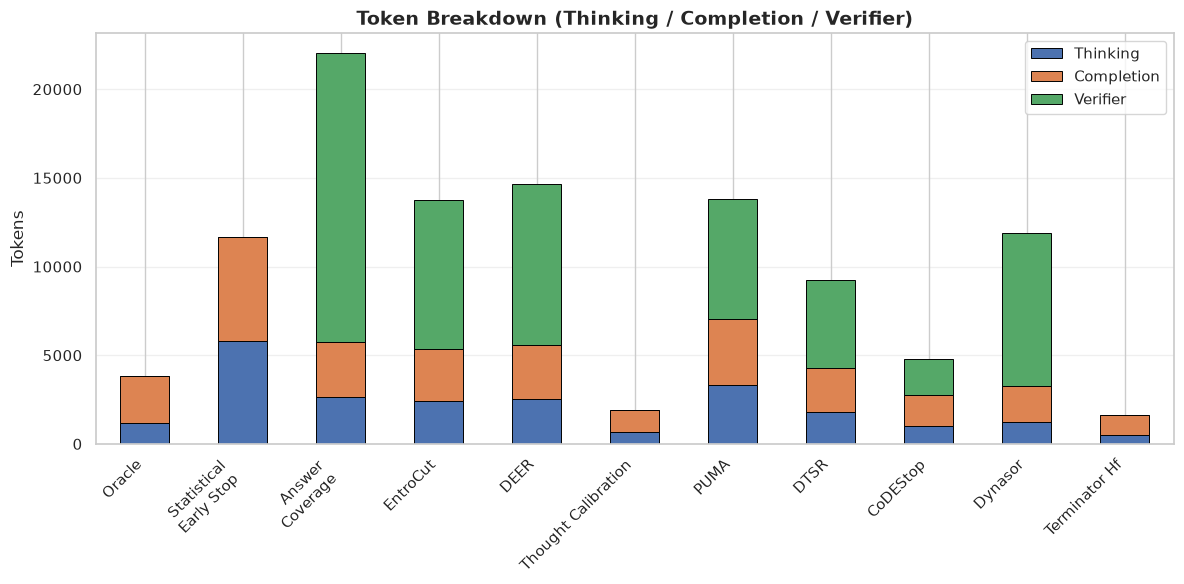

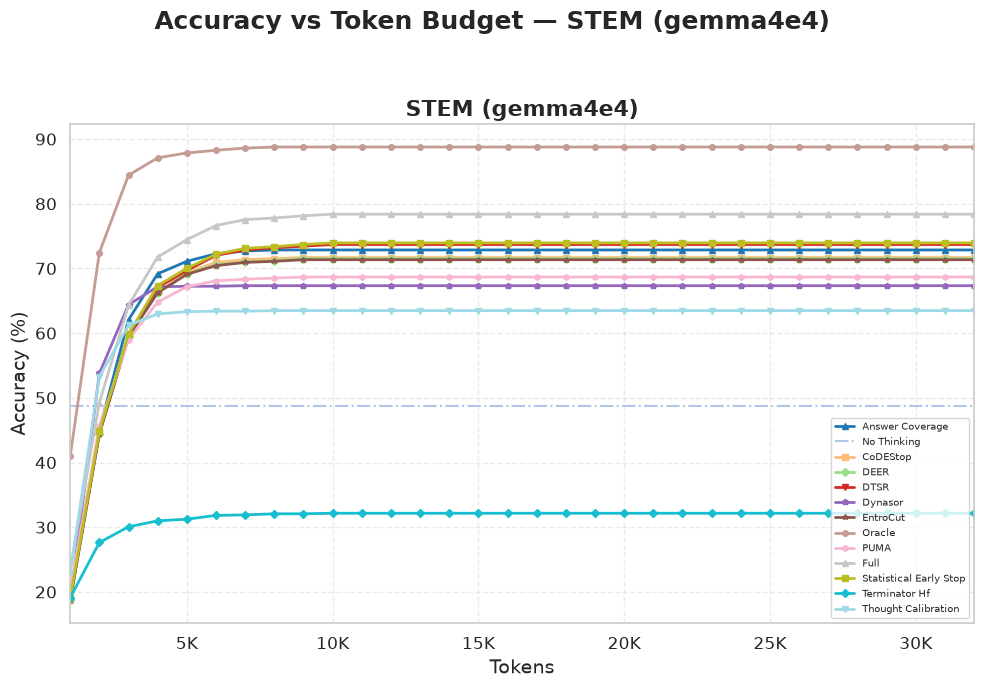

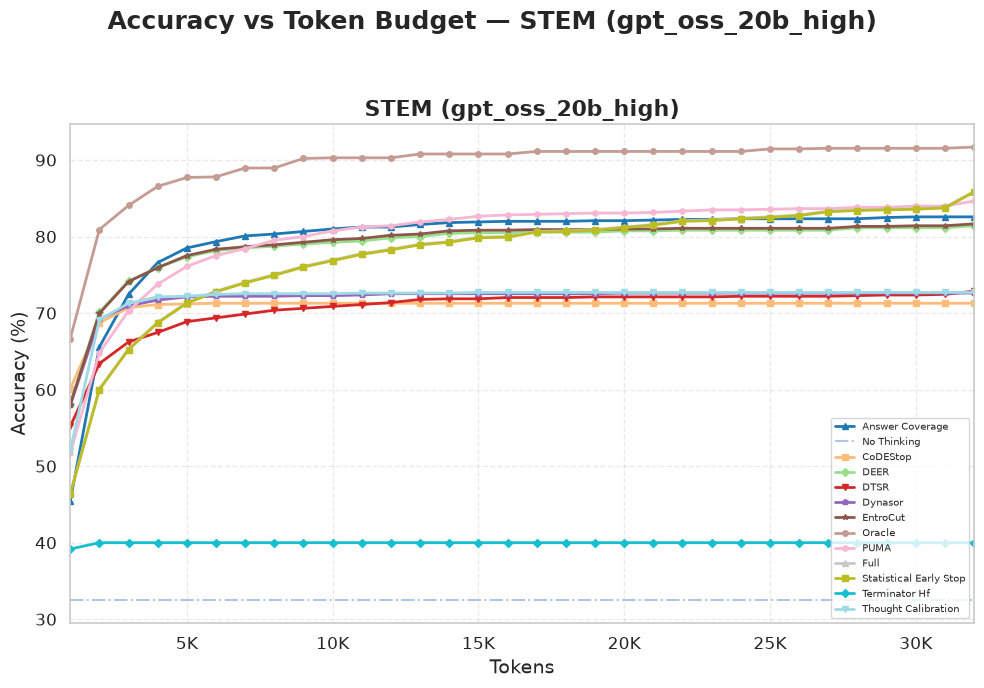

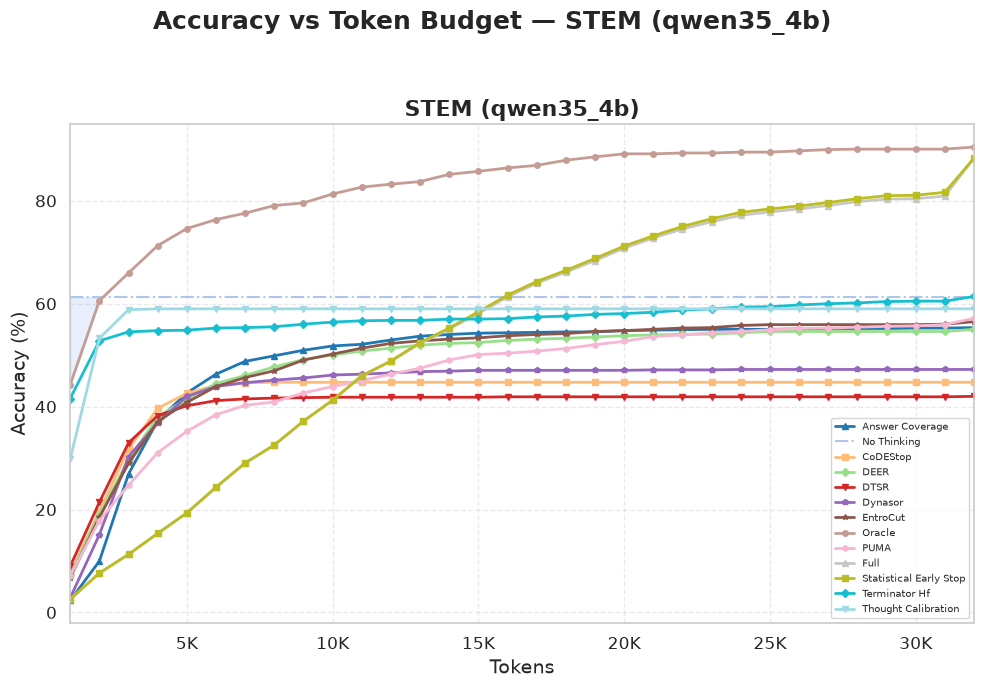

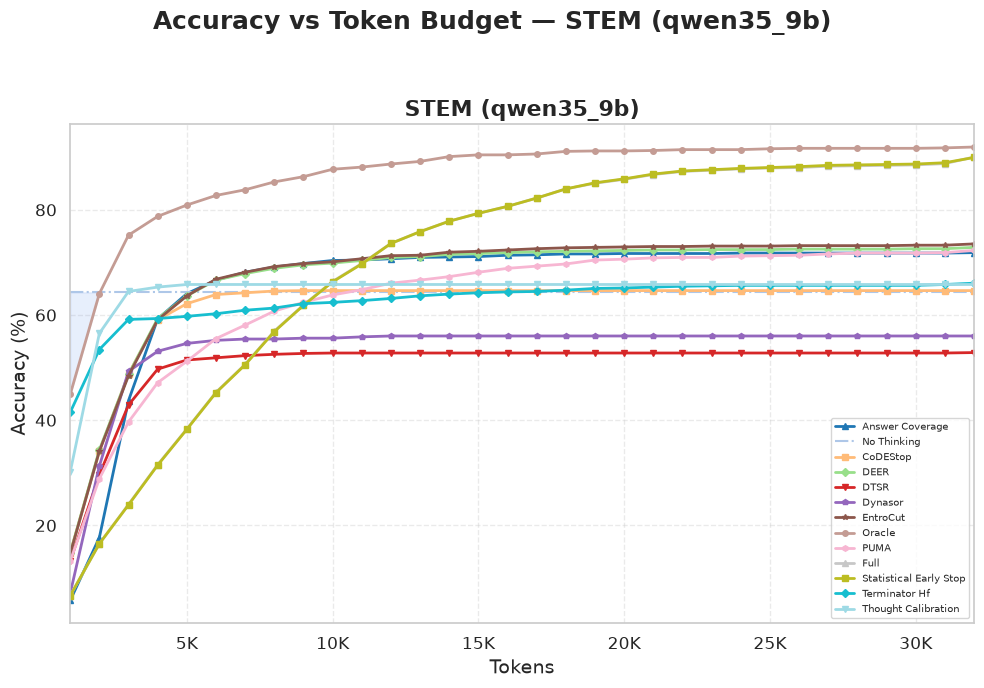

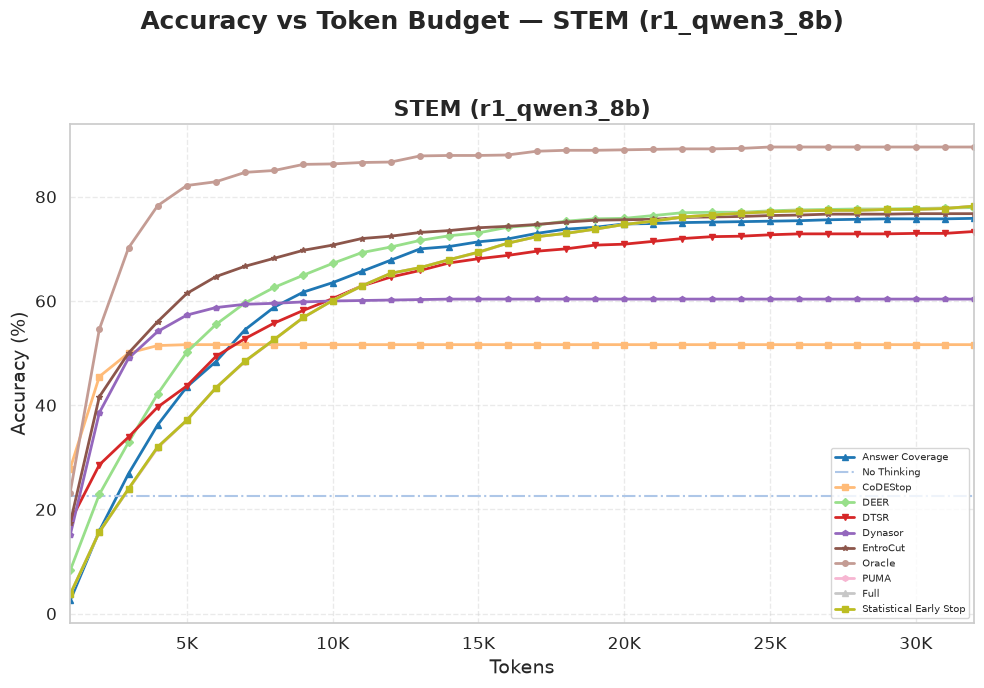

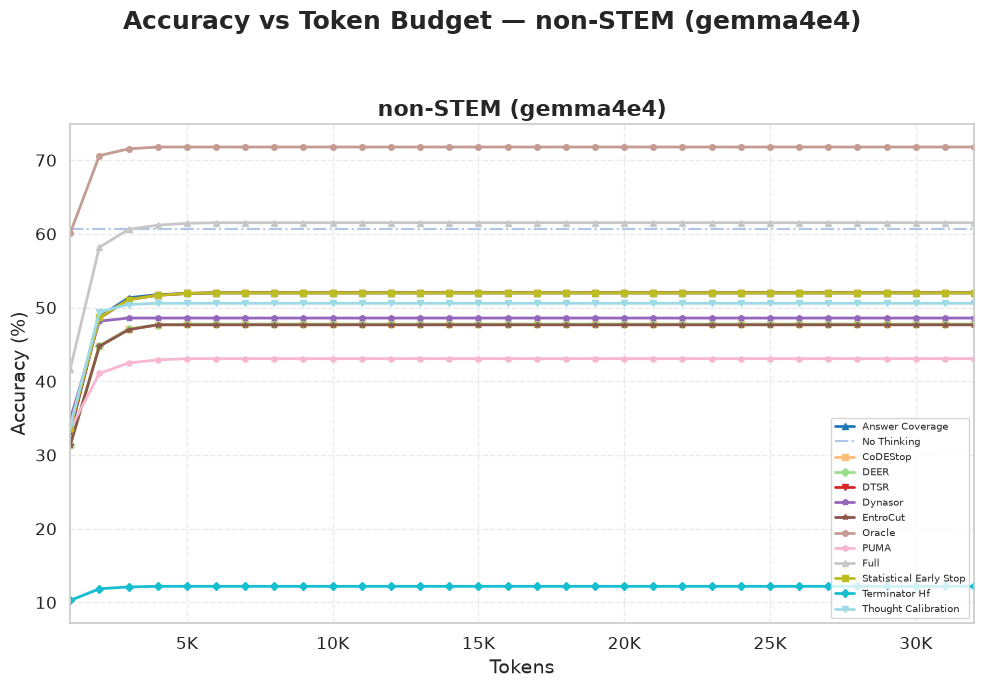

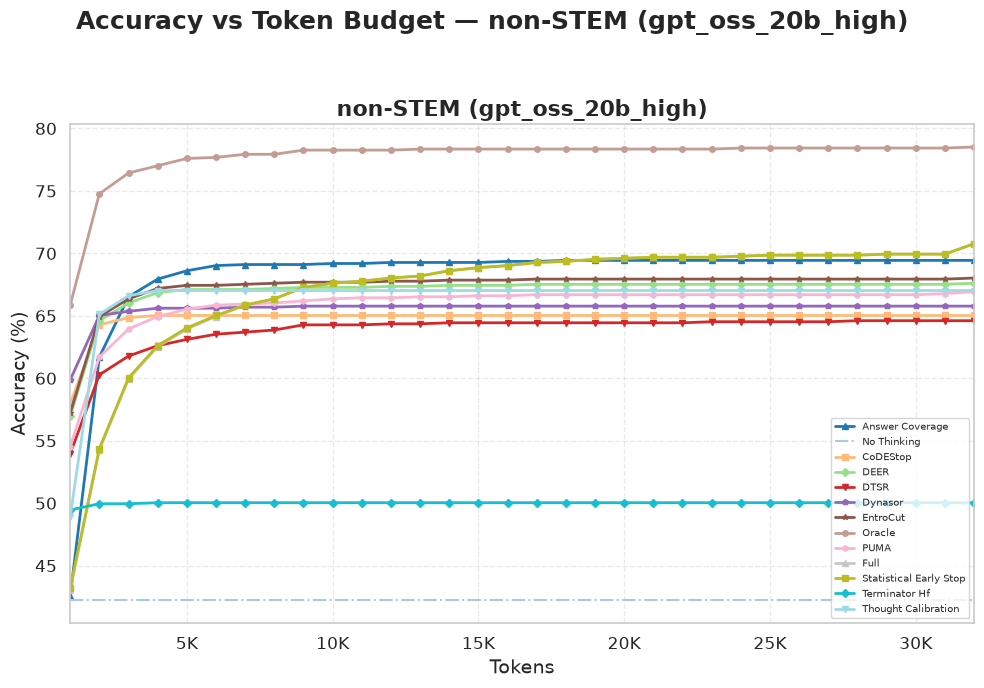

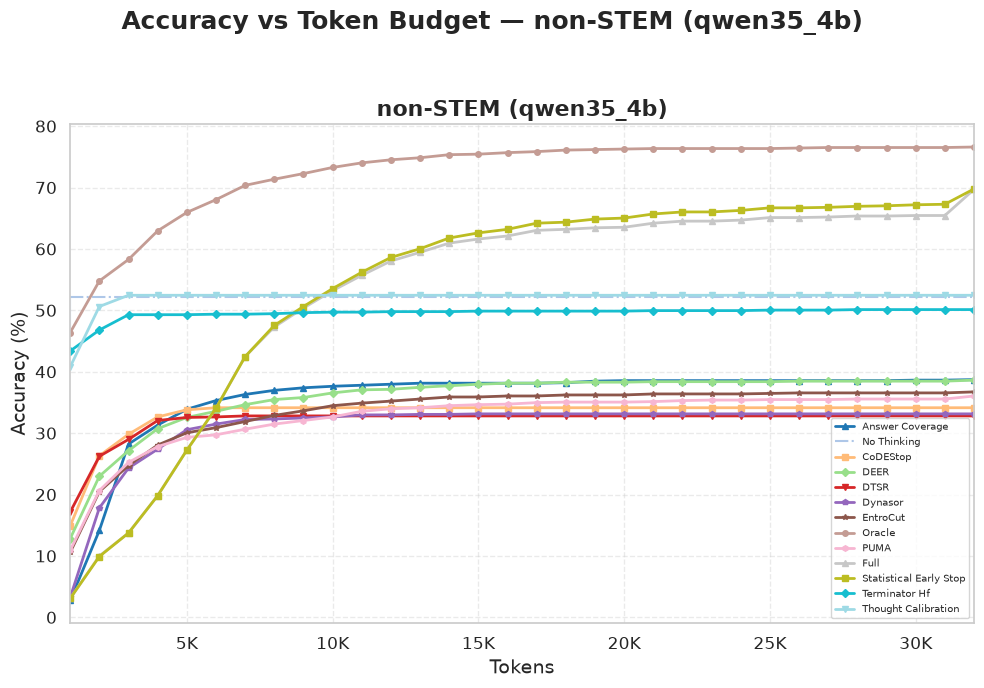

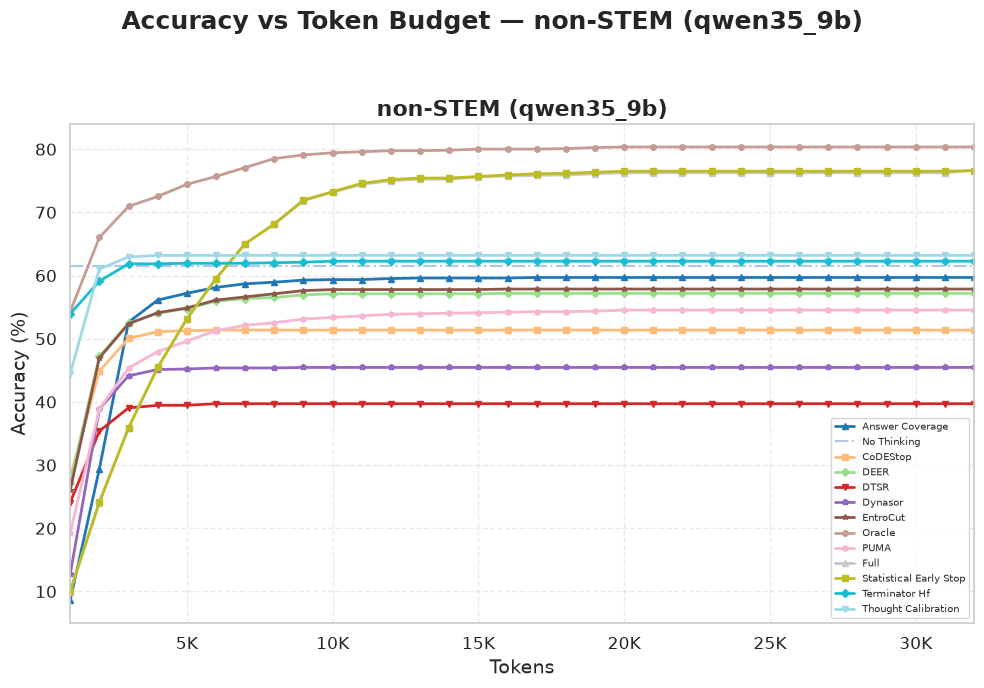

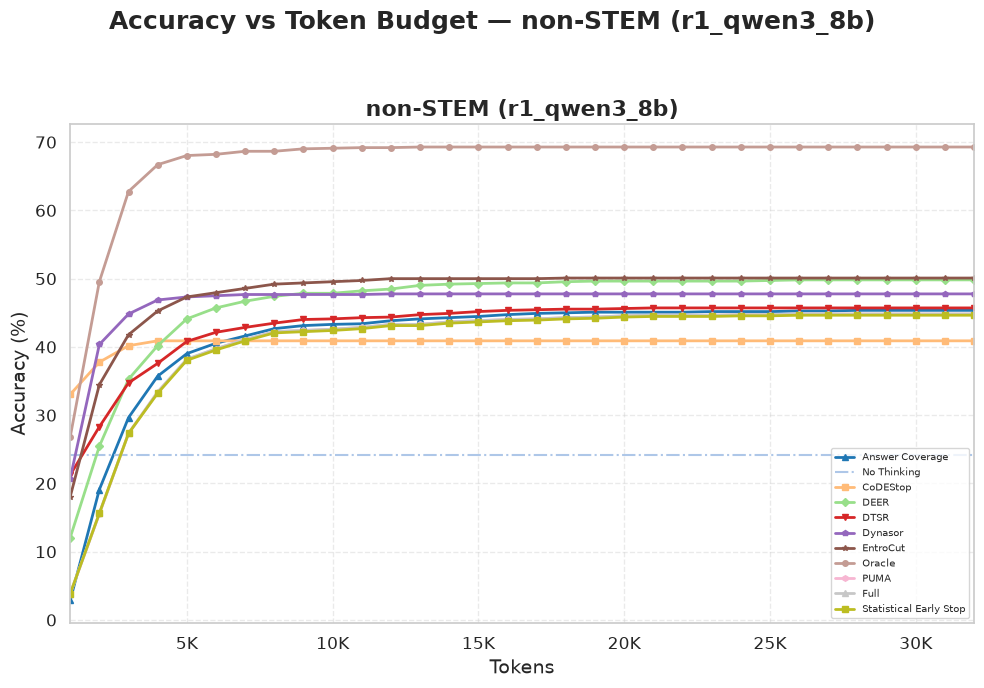

/tmp/ipykernel_3054371/4061338017.py:254: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=vp, x="method", y="position", order=order, palette="viridis")


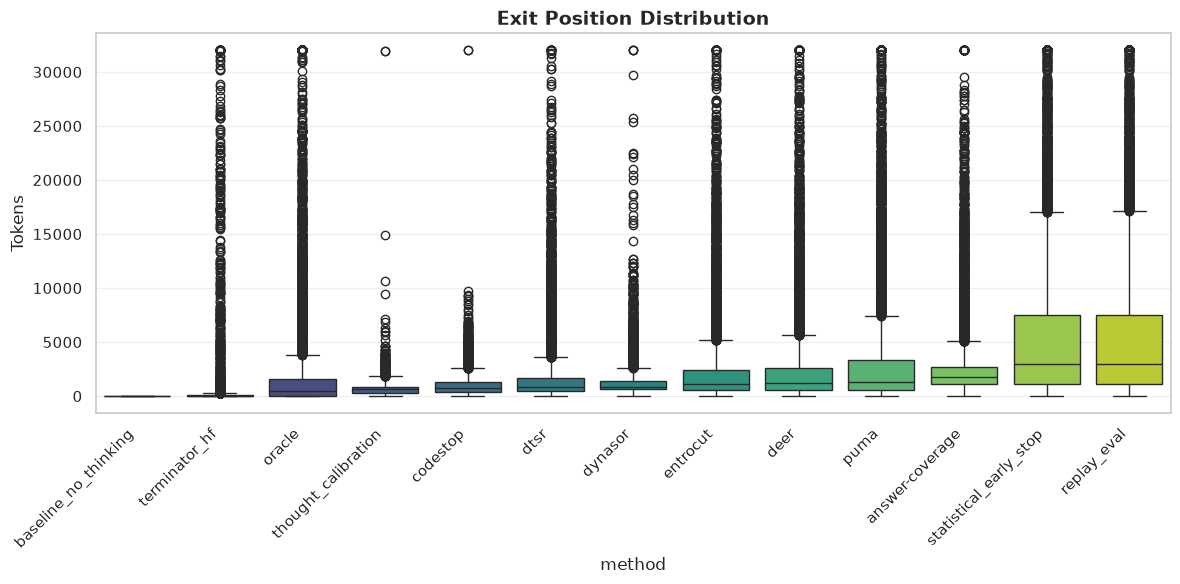

In [30]:
draw_all_visualizations(df_collapsed, summary)

In [31]:
exported_visualizations = draw_all_visualizations_export(
    df_collapsed,
    summary,
    output_dir=str(RESULTS_ROOT / PARTITION_LEVEL / "figures"),
)
print(f"Saved {len(exported_visualizations)} visualization images in the partition figures directory.")

Saved 11 visualization images in the partition figures directory.


In [32]:
# raise SystemExit("Analysis complete. Exiting script.")

### Draw aggregate performance visualizations

Renders the summary bar charts, stacked token-cost breakdown, per-benchmark/model accuracy-versus-budget curves, and exit-position distributions. Token values are clipped to 32K only in a plotting copy; analytical values remain unchanged, and accuracy curves use the full question count as their denominator.


# Continuation reasoning-error rate



In [33]:

continuation_error_stats, continuation_trace_stats = (
    calculate_continuation_error_rates(df)
)
print_continuation_error_report(continuation_error_stats)


FLATTENED CONTINUATION REASONING-ERROR RATE (%)
| scope   | benchmark   | model            |   exit_t_observations |   question_clusters |   mean_reasoning_budget |   mean_later_attempts_per_trace |   later_correct_% |   q_hat_% |   ci_lower_% |   ci_upper_% | support   |
|:--------|:------------|:-----------------|----------------------:|--------------------:|------------------------:|--------------------------------:|------------------:|----------:|-------------:|-------------:|:----------|
| stratum | STEM        | gemma4e4         |                  4801 |                1075 |                   878.3 |                           17.9  |             88.32 |     11.68 |        10.1  |        13.27 | poor      |
| stratum | STEM        | gpt_oss_20b_high |                  6941 |                1117 |                  2101.1 |                           14.91 |             94.73 |      5.27 |         4.41 |         6.14 | poor      |
| stratum | STEM        | qwen35_4b        |        